In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

### Importanto base de dados Jan/2025 - Maio/2026

Baixar o dataset aqui: [GOOGLE DRIVE](https://drive.google.com/file/d/1oGBedoc72Frt1Hzm4rPuCQyP-7FREf0K/view?usp=sharing)

In [2]:
df_com_restricao_final = pd.read_csv('/content/df_com_restricao_2025_2026.csv')
df_com_restricao_final.head()

,data_hora_utc,geracao_alvo_mwmed,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","UMIDADE RELATIVA DO AR, HORARIA(%)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",Radiação (Wh/m2),"PRECIPITACAO ERA5, HORARIA(mm)"
0,2025-01-01 00:00:00,0.0,26.2,69.0,965.1,0.0,0.000000
1,2025-01-01 01:00:00,0.0,25.1,71.0,965.7,0.0,0.000000
2,2025-01-01 02:00:00,0.0,25.2,70.0,966.4,0.0,0.016689
3,2025-01-01 03:00:00,0.0,25.2,71.0,966.4,0.0,0.055790
4,2025-01-01 04:00:00,0.0,24.4,78.0,966.1,0.0,0.017643


In [3]:
df_com_restricao_final['data_hora_utc'] = pd.to_datetime(
    df_com_restricao_final['data_hora_utc']
)

In [4]:
df_com_restricao_final.tail()

,data_hora_utc,geracao_alvo_mwmed,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","UMIDADE RELATIVA DO AR, HORARIA(%)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",Radiação (Wh/m2),"PRECIPITACAO ERA5, HORARIA(mm)"
12379,2026-05-31 19:00:00,19.4020,25.3506,49.770,972.4,233.0285,0.0
12380,2026-05-31 20:00:00,3.0725,24.2322,52.339,972.6,43.4508,0.0
12381,2026-05-31 21:00:00,0.0000,21.9523,60.954,973.0,0.0000,0.0
12382,2026-05-31 22:00:00,0.0000,21.1477,64.431,973.5,0.0000,0.0
12383,2026-05-31 23:00:00,0.0000,19.9000,69.862,974.1,0.0000,0.0


In [5]:
df_com_restricao_final['data_hora_utc']
print("Dimensão:", df_com_restricao_final.shape)

print("\nValores nulos:")
print(df_com_restricao_final.isna().sum())

print("\nDuplicatas:")
print(df_com_restricao_final['data_hora_utc'].duplicated().sum())

print("\nPeríodo:")
print(df_com_restricao_final['data_hora_utc'].min())
print(df_com_restricao_final['data_hora_utc'].max())

print("\nIntervalos:")
print(df_com_restricao_final['data_hora_utc'].diff().value_counts())

Dimensão: (12384, 7)

Valores nulos:
data_hora_utc                                           0
geracao_alvo_mwmed                                      0
TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)             0
UMIDADE RELATIVA DO AR, HORARIA(%)                      0
PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)    0
Radiação (Wh/m2)                                        0
PRECIPITACAO ERA5, HORARIA(mm)                          0
dtype: int64

Duplicatas:
0

Período:
2025-01-01 00:00:00
2026-05-31 23:00:00

Intervalos:
data_hora_utc
0 days 01:00:00    12383
Name: count, dtype: int64


### Criar o dataframe base

* Treino: alvo entre janeiro e 31/08/2025
* Validação: alvo entre 01/09/2025 e 31/10/2025
* Teste: alvo entre 01/11/2025 e 31/05/2026

df_base contém todo o período, base para todos os horizontes.

In [6]:
df_base = (
    df_com_restricao_final
    .sort_values('data_hora_utc')
    .reset_index(drop=True)
    .rename(columns={
        'TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)': 'temperatura_t',
        'UMIDADE RELATIVA DO AR, HORARIA(%)': 'umidade_t',
        'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)': 'pressao_t',
        'Radiação (Wh/m2)': 'radiacao_t',
        'PRECIPITACAO ERA5, HORARIA(mm)': 'precipitacao_t'
    })
    .copy()
)

df_base['geracao_t'] = df_base['geracao_alvo_mwmed']

df_base['geracao_t-1'] = df_base['geracao_t'].shift(1)
df_base['geracao_t-2'] = df_base['geracao_t'].shift(2)
df_base['geracao_t-3'] = df_base['geracao_t'].shift(3)
df_base['geracao_t-24'] = df_base['geracao_t'].shift(24)

df_base['radiacao_t-1'] = df_base['radiacao_t'].shift(1)
df_base['radiacao_t-2'] = df_base['radiacao_t'].shift(2)

Experimento: blocos crescentes de informação (estudo de ablação)   

E0 - E1: Revela quanto a inércia auto-regressiva e a informação temporal explicam a geração.  
E1 - E2: Mede o ganho trazido pela variável física primária (radiação solar).  
E2 - E3: Avalia se o vetor meteorológico secundário (temperatura, umidade, pressão, precipitação) agrega capacidade preditiva além da radiação.

In [7]:
features_e1 = [
    'geracao_t',
    'geracao_t-1',
    'geracao_t-2',
    'geracao_t-3',
    'geracao_t-24',
    'hour_sin',
    'hour_cos',
    'day_of_year_sin',
    'day_of_year_cos'
]

features_e2 = features_e1 + [
    'radiacao_t',
    'radiacao_t-1',
    'radiacao_t-2'
]

features_e3 = features_e2 + [
    'temperatura_t',
    'umidade_t',
    'pressao_t',
    'precipitacao_t'
]

In [8]:
def criar_target_horizonte(df, h):
    df_h = df.copy()

    df_h[f'target_t{h}'] = (
        df_h['geracao_alvo_mwmed'].shift(-h)
    )

    df_h['target_datetime'] = (
        df_h['data_hora_utc'].shift(-h)
    )

    df_h['target_hour'] = df_h['target_datetime'].dt.hour
    df_h['target_day_of_year'] = df_h['target_datetime'].dt.dayofyear

    df_h['hour_sin'] = np.sin(
        2 * np.pi * df_h['target_hour'] / 24
    )

    df_h['hour_cos'] = np.cos(
        2 * np.pi * df_h['target_hour'] / 24
    )

    df_h['day_of_year_sin'] = np.sin(
        2 * np.pi * df_h['target_day_of_year'] / 365
    )

    df_h['day_of_year_cos'] = np.cos(
        2 * np.pi * df_h['target_day_of_year'] / 365
    )

    return df_h

### Construção dos targets

In [9]:
df_base.tail()

,data_hora_utc,geracao_alvo_mwmed,temperatura_t,umidade_t,pressao_t,radiacao_t,precipitacao_t,geracao_t,geracao_t-1,geracao_t-2,geracao_t-3,geracao_t-24,radiacao_t-1,radiacao_t-2
12379,2026-05-31 19:00:00,19.4020,25.3506,49.770,972.4,233.0285,0.0,19.4020,43.4640,48.6400,51.5580,27.2115,433.7300,595.9823
12380,2026-05-31 20:00:00,3.0725,24.2322,52.339,972.6,43.4508,0.0,3.0725,19.4020,43.4640,48.6400,3.2350,233.0285,433.7300
12381,2026-05-31 21:00:00,0.0000,21.9523,60.954,973.0,0.0000,0.0,0.0000,3.0725,19.4020,43.4640,0.0000,43.4508,233.0285
12382,2026-05-31 22:00:00,0.0000,21.1477,64.431,973.5,0.0000,0.0,0.0000,0.0000,3.0725,19.4020,0.0000,0.0000,43.4508
12383,2026-05-31 23:00:00,0.0000,19.9000,69.862,974.1,0.0000,0.0,0.0000,0.0000,0.0000,3.0725,0.0000,0.0000,0.0000


In [10]:
df_h1 = criar_target_horizonte(df_base, 1)

In [11]:
df_h12 = criar_target_horizonte(df_base, 12)

In [16]:
df_h12.head()

,data_hora_utc,geracao_alvo_mwmed,temperatura_t,umidade_t,pressao_t,radiacao_t,precipitacao_t,geracao_t,geracao_t-1,geracao_t-2,...,radiacao_t-1,radiacao_t-2,target_t12,target_datetime,target_hour,target_day_of_year,hour_sin,hour_cos,day_of_year_sin,day_of_year_cos
0,2025-01-01 00:00:00,0.0,26.2,69.0,965.1,0.0,0.000000,0.0,NaN,NaN,...,NaN,NaN,36.5205,2025-01-01 12:00:00,12.0,1.0,1.224647e-16,-1.000000,0.017213,0.999852
1,2025-01-01 01:00:00,0.0,25.1,71.0,965.7,0.0,0.000000,0.0,0.0,NaN,...,0.0,NaN,43.7875,2025-01-01 13:00:00,13.0,1.0,-2.588190e-01,-0.965926,0.017213,0.999852
2,2025-01-01 02:00:00,0.0,25.2,70.0,966.4,0.0,0.016689,0.0,0.0,0.0,...,0.0,0.0,47.2645,2025-01-01 14:00:00,14.0,1.0,-5.000000e-01,-0.866025,0.017213,0.999852
3,2025-01-01 03:00:00,0.0,25.2,71.0,966.4,0.0,0.055790,0.0,0.0,0.0,...,0.0,0.0,40.5645,2025-01-01 15:00:00,15.0,1.0,-7.071068e-01,-0.707107,0.017213,0.999852
4,2025-01-01 04:00:00,0.0,24.4,78.0,966.1,0.0,0.017643,0.0,0.0,0.0,...,0.0,0.0,46.7945,2025-01-01 16:00:00,16.0,1.0,-8.660254e-01,-0.500000,0.017213,0.999852


In [12]:
df_h24 = criar_target_horizonte(df_base, 24)

In [18]:
df_h24.head()

,data_hora_utc,geracao_alvo_mwmed,temperatura_t,umidade_t,pressao_t,radiacao_t,precipitacao_t,geracao_t,geracao_t-1,geracao_t-2,...,radiacao_t-1,radiacao_t-2,target_t24,target_datetime,target_hour,target_day_of_year,hour_sin,hour_cos,day_of_year_sin,day_of_year_cos
0,2025-01-01 00:00:00,0.0,26.2,69.0,965.1,0.0,0.000000,0.0,NaN,NaN,...,NaN,NaN,0.0,2025-01-02 00:00:00,0.0,2.0,0.000000,1.000000,0.034422,0.999407
1,2025-01-01 01:00:00,0.0,25.1,71.0,965.7,0.0,0.000000,0.0,0.0,NaN,...,0.0,NaN,0.0,2025-01-02 01:00:00,1.0,2.0,0.258819,0.965926,0.034422,0.999407
2,2025-01-01 02:00:00,0.0,25.2,70.0,966.4,0.0,0.016689,0.0,0.0,0.0,...,0.0,0.0,0.0,2025-01-02 02:00:00,2.0,2.0,0.500000,0.866025,0.034422,0.999407
3,2025-01-01 03:00:00,0.0,25.2,71.0,966.4,0.0,0.055790,0.0,0.0,0.0,...,0.0,0.0,0.0,2025-01-02 03:00:00,3.0,2.0,0.707107,0.707107,0.034422,0.999407
4,2025-01-01 04:00:00,0.0,24.4,78.0,966.1,0.0,0.017643,0.0,0.0,0.0,...,0.0,0.0,0.0,2025-01-02 04:00:00,4.0,2.0,0.866025,0.500000,0.034422,0.999407


In [13]:
for h, df in [
    (1, df_h1),
    (12, df_h12),
    (24, df_h24)
]:
    target = f'target_t{h}'

    print(f'\n===== Horizonte {h}h =====')
    print('Total de linhas:', len(df))
    print('Targets nulos:', df[target].isna().sum())
    print('target_datetime nulos:', df['target_datetime'].isna().sum())

    validos = df.dropna(subset=[target, 'target_datetime'])

    print('Primeiro X:', validos['data_hora_utc'].min())
    print('Último X:', validos['data_hora_utc'].max())
    print('Primeiro alvo:', validos['target_datetime'].min())
    print('Último alvo:', validos['target_datetime'].max())


===== Horizonte 1h =====
Total de linhas: 12384
Targets nulos: 1
target_datetime nulos: 1
Primeiro X: 2025-01-01 00:00:00
Último X: 2026-05-31 22:00:00
Primeiro alvo: 2025-01-01 01:00:00
Último alvo: 2026-05-31 23:00:00

===== Horizonte 12h =====
Total de linhas: 12384
Targets nulos: 12
target_datetime nulos: 12
Primeiro X: 2025-01-01 00:00:00
Último X: 2026-05-31 11:00:00
Primeiro alvo: 2025-01-01 12:00:00
Último alvo: 2026-05-31 23:00:00

===== Horizonte 24h =====
Total de linhas: 12384
Targets nulos: 24
target_datetime nulos: 24
Primeiro X: 2025-01-01 00:00:00
Último X: 2026-05-30 23:00:00
Primeiro alvo: 2025-01-02 00:00:00
Último alvo: 2026-05-31 23:00:00


### Divisão temporal

In [14]:
train_start = pd.Timestamp('2025-01-03 00:00:00')
train_end   = pd.Timestamp('2025-08-31 23:00:00')

val_start   = pd.Timestamp('2025-09-01 00:00:00')
val_end     = pd.Timestamp('2025-10-31 23:00:00')

test_start  = pd.Timestamp('2025-11-01 00:00:00')
test_end    = pd.Timestamp('2026-05-31 23:00:00')

In [15]:
def criar_splits_horizonte(df, h):
    target = f'target_t{h}'

    df = df.dropna(
        subset=[target, 'target_datetime']
    ).copy()

    treino = df[
        (df['target_datetime'] >= train_start) &
        (df['target_datetime'] <= train_end)
    ].copy()

    validacao = df[
        (df['target_datetime'] >= val_start) &
        (df['target_datetime'] <= val_end)
    ].copy()

    teste = df[
        (df['target_datetime'] >= test_start) &
        (df['target_datetime'] <= test_end)
    ].copy()

    return treino, validacao, teste

In [16]:
train_h1, val_h1, test_h1 = criar_splits_horizonte(df_h1, 1)

train_h12, val_h12, test_h12 = criar_splits_horizonte(df_h12, 12)

train_h24, val_h24, test_h24 = criar_splits_horizonte(df_h24, 24)

In [17]:
for h, train, val, test in [
    (1, train_h1, val_h1, test_h1),
    (12, train_h12, val_h12, test_h12),
    (24, train_h24, val_h24, test_h24)
]:
    print(f'\n===== Horizonte {h}h =====')

    print(
        'Treino:',
        len(train),
        '|',
        train['target_datetime'].min(),
        '→',
        train['target_datetime'].max()
    )

    print(
        'Validação:',
        len(val),
        '|',
        val['target_datetime'].min(),
        '→',
        val['target_datetime'].max()
    )

    print(
        'Teste:',
        len(test),
        '|',
        test['target_datetime'].min(),
        '→',
        test['target_datetime'].max()
    )


===== Horizonte 1h =====
Treino: 5784 | 2025-01-03 00:00:00 → 2025-08-31 23:00:00
Validação: 1464 | 2025-09-01 00:00:00 → 2025-10-31 23:00:00
Teste: 5088 | 2025-11-01 00:00:00 → 2026-05-31 23:00:00

===== Horizonte 12h =====
Treino: 5784 | 2025-01-03 00:00:00 → 2025-08-31 23:00:00
Validação: 1464 | 2025-09-01 00:00:00 → 2025-10-31 23:00:00
Teste: 5088 | 2025-11-01 00:00:00 → 2026-05-31 23:00:00

===== Horizonte 24h =====
Treino: 5784 | 2025-01-03 00:00:00 → 2025-08-31 23:00:00
Validação: 1464 | 2025-09-01 00:00:00 → 2025-10-31 23:00:00
Teste: 5088 | 2025-11-01 00:00:00 → 2026-05-31 23:00:00


In [18]:
for h, train, val, test in [
    (1, train_h1, val_h1, test_h1),
    (12, train_h12, val_h12, test_h12),
    (24, train_h24, val_h24, test_h24)
]:
    print(f'\n===== Horizonte {h}h =====')

    for nome_split, df_split in [
        ('Treino', train),
        ('Validação', val),
        ('Teste', test)
    ]:
        print(f'\n{nome_split}')

        print('E1 NaNs:', df_split[features_e1].isna().sum().sum())
        print('E2 NaNs:', df_split[features_e2].isna().sum().sum())
        print('E3 NaNs:', df_split[features_e3].isna().sum().sum())


===== Horizonte 1h =====

Treino
E1 NaNs: 0
E2 NaNs: 0
E3 NaNs: 0

Validação
E1 NaNs: 0
E2 NaNs: 0
E3 NaNs: 0

Teste
E1 NaNs: 0
E2 NaNs: 0
E3 NaNs: 0

===== Horizonte 12h =====

Treino
E1 NaNs: 0
E2 NaNs: 0
E3 NaNs: 0

Validação
E1 NaNs: 0
E2 NaNs: 0
E3 NaNs: 0

Teste
E1 NaNs: 0
E2 NaNs: 0
E3 NaNs: 0

===== Horizonte 24h =====

Treino
E1 NaNs: 0
E2 NaNs: 0
E3 NaNs: 0

Validação
E1 NaNs: 0
E2 NaNs: 0
E3 NaNs: 0

Teste
E1 NaNs: 0
E2 NaNs: 0
E3 NaNs: 0


In [19]:
splits_por_horizonte = {
    1: {
        'train': train_h1,
        'val': val_h1,
        'test': test_h1
    },
    12: {
        'train': train_h12,
        'val': val_h12,
        'test': test_h12
    },
    24: {
        'train': train_h24,
        'val': val_h24,
        'test': test_h24
    }
}

conjuntos_features = {
    'E1': features_e1,
    'E2': features_e2,
    'E3': features_e3
}

In [20]:
dados_modelagem = {}

for h, splits in splits_por_horizonte.items():
    target = f'target_t{h}'

    dados_modelagem[h] = {}

    for experimento, features in conjuntos_features.items():

        dados_modelagem[h][experimento] = {
            'X_train': splits['train'][features].copy(),
            'y_train': splits['train'][target].copy(),

            'X_val': splits['val'][features].copy(),
            'y_val': splits['val'][target].copy(),

            'X_test': splits['test'][features].copy(),
            'y_test': splits['test'][target].copy()
        }

dados_modelagem[1]['E1']['X_train'] == horizonte 1h + experimento 1 + treino

In [21]:
for h in [1, 12, 24]:
    print(f'\n===== Horizonte {h}h =====')

    for experimento in ['E1', 'E2', 'E3']:
        dados = dados_modelagem[h][experimento]

        print(
            experimento,
            '| Train:', dados['X_train'].shape,
            '| Val:', dados['X_val'].shape,
            '| Test:', dados['X_test'].shape
        )


===== Horizonte 1h =====
E1 | Train: (5784, 9) | Val: (1464, 9) | Test: (5088, 9)
E2 | Train: (5784, 12) | Val: (1464, 12) | Test: (5088, 12)
E3 | Train: (5784, 16) | Val: (1464, 16) | Test: (5088, 16)

===== Horizonte 12h =====
E1 | Train: (5784, 9) | Val: (1464, 9) | Test: (5088, 9)
E2 | Train: (5784, 12) | Val: (1464, 12) | Test: (5088, 12)
E3 | Train: (5784, 16) | Val: (1464, 16) | Test: (5088, 16)

===== Horizonte 24h =====
E1 | Train: (5784, 9) | Val: (1464, 9) | Test: (5088, 9)
E2 | Train: (5784, 12) | Val: (1464, 12) | Test: (5088, 12)
E3 | Train: (5784, 16) | Val: (1464, 16) | Test: (5088, 16)


### Imports Modelos, Métricas

In [22]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.inspection import permutation_importance

### Baseline de Persistência

* Persistência Simples (Método Naive clássico): o valor futuro será exatamente igual ao valor mais recente observado    
* Persistência Sazonal (Método Baive Sazonal): estimar o valor futuro com base na mesma estação do período anterior

https://otexts.com/fpp3/toolbox.html

In [ ]:
resultados_persistencia_val = []

for h in [1, 12, 24]:
    val = splits_por_horizonte[h]['val']

    y_true = val[f'target_t{h}']
    y_pred = val['geracao_t']

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    resultados_persistencia_val.append({
        'horizonte': h,
        'modelo': 'Persistência',
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

df_persistencia_val = pd.DataFrame(resultados_persistencia_val)

df_persistencia_val

,horizonte,modelo,MAE,RMSE,R2
0,1,Persistência,5.217168,9.445246,0.810303
1,12,Persistência,32.985026,38.570628,-2.163347
2,24,Persistência,5.978828,12.265878,0.680088


In [ ]:
serie_geracao = (
    df_base
    .set_index('data_hora_utc')['geracao_alvo_mwmed']
)

resultados_persistencia_sazonal_val = []

for h in [1, 12, 24]:
    val = splits_por_horizonte[h]['val'].copy()

    instante_referencia = (
        val['target_datetime'] - pd.Timedelta(hours=24)
    )

    y_true = val[f'target_t{h}']

    y_pred = instante_referencia.map(serie_geracao)

    mask = y_true.notna() & y_pred.notna()

    mae = mean_absolute_error(
        y_true[mask],
        y_pred[mask]
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true[mask],
            y_pred[mask]
        )
    )

    r2 = r2_score(
        y_true[mask],
        y_pred[mask]
    )

    resultados_persistencia_sazonal_val.append({
        'horizonte': h,
        'modelo': 'Persistência sazonal 24h',
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

df_persistencia_sazonal_val = pd.DataFrame(
    resultados_persistencia_sazonal_val
)

df_persistencia_sazonal_val

,horizonte,modelo,MAE,RMSE,R2
0,1,Persistência sazonal 24h,5.978828,12.265878,0.680088
1,12,Persistência sazonal 24h,5.978828,12.265878,0.680088
2,24,Persistência sazonal 24h,5.978828,12.265878,0.680088


### SVR

#### Tuning

In [30]:
svr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR(kernel='rbf'))
])

param_grid_svr = {
    'svr__C': [500, 1000, 2000, 5000],
    'svr__epsilon': [0.1, 0.2, 0.5, 0.8, 1.0],
    'svr__gamma': [0.0001, 0.001, 0.005, 0.01, 0.02]
}

In [29]:
def tunar_svr(h, experimento):
    dados = dados_modelagem[h][experimento]

    X_train = dados['X_train']
    y_train = dados['y_train']

    tscv = TimeSeriesSplit(
        n_splits=5,
        gap=h
    )

    grid = GridSearchCV(
        estimator=clone(svr_pipeline),
        param_grid=param_grid_svr,
        scoring='neg_root_mean_squared_error',
        cv=tscv,
        n_jobs=-1,
        verbose=1
    )

    grid.fit(X_train, y_train)

    return grid

Busca dos hiperparametros   
treino → GridSearch/TimeSeriesSplit → melhores hiperparâmetros → validação externa

In [ ]:
grid_svr_h1_e1 = tunar_svr(1, 'E1')

print('Melhores parâmetros:')
print(grid_svr_h1_e1.best_params_)

print('\nMelhor RMSE médio no CV:')
print(-grid_svr_h1_e1.best_score_)

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Melhores parâmetros:
{'svr__C': 2000, 'svr__epsilon': 0.2, 'svr__gamma': 0.01}

Melhor RMSE médio no CV:
7.0931483941550635


In [ ]:
resultados_grid_svr = {
    1: {},
    12: {},
    24: {}
}

# H1-E1
resultados_grid_svr[1]['E1'] = grid_svr_h1_e1

for h in [1, 12, 24]:
    for experimento in ['E1', 'E2', 'E3']:

        if h == 1 and experimento == 'E1':
            continue

        print(f'\n===== SVR | Horizonte {h}h | {experimento} =====')

        grid = tunar_svr(h, experimento)

        resultados_grid_svr[h][experimento] = grid

        print('Melhores parâmetros:')
        print(grid.best_params_)

        print('RMSE médio CV:')
        print(-grid.best_score_)


===== SVR | Horizonte 1h | E2 =====
Fitting 5 folds for each of 100 candidates, totalling 500 fits
Melhores parâmetros:
{'svr__C': 5000, 'svr__epsilon': 0.8, 'svr__gamma': 0.005}
RMSE médio CV:
6.684297010422796

===== SVR | Horizonte 1h | E3 =====
Fitting 5 folds for each of 100 candidates, totalling 500 fits
Melhores parâmetros:
{'svr__C': 1000, 'svr__epsilon': 1.0, 'svr__gamma': 0.005}
RMSE médio CV:
6.778444848348083

===== SVR | Horizonte 12h | E1 =====
Fitting 5 folds for each of 100 candidates, totalling 500 fits
Melhores parâmetros:
{'svr__C': 500, 'svr__epsilon': 0.1, 'svr__gamma': 0.01}
RMSE médio CV:
10.778091633747152

===== SVR | Horizonte 12h | E2 =====
Fitting 5 folds for each of 100 candidates, totalling 500 fits
Melhores parâmetros:
{'svr__C': 500, 'svr__epsilon': 0.1, 'svr__gamma': 0.01}
RMSE médio CV:
11.069256668601664

===== SVR | Horizonte 12h | E3 =====
Fitting 5 folds for each of 100 candidates, totalling 500 fits
Melhores parâmetros:
{'svr__C': 2000, 'svr__eps

In [ ]:
resumo_svr_cv = []

for h in [1, 12, 24]:
    for experimento in ['E1', 'E2', 'E3']:

        grid = resultados_grid_svr[h][experimento]

        resumo_svr_cv.append({
            'horizonte': h,
            'experimento': experimento,
            'C': grid.best_params_['svr__C'],
            'epsilon': grid.best_params_['svr__epsilon'],
            'gamma': grid.best_params_['svr__gamma'],
            'RMSE_CV': -grid.best_score_
        })

df_resumo_svr_cv = pd.DataFrame(resumo_svr_cv)

df_resumo_svr_cv

,horizonte,experimento,C,epsilon,gamma,RMSE_CV
0,1,E1,2000,0.2,0.0100,7.093148
1,1,E2,5000,0.8,0.0050,6.684297
2,1,E3,1000,1.0,0.0050,6.778445
3,12,E1,500,0.1,0.0100,10.778092
4,12,E2,500,0.1,0.0100,11.069257
5,12,E3,2000,0.2,0.0050,10.073512
6,24,E1,500,1.0,0.0010,10.129464
7,24,E2,500,1.0,0.0001,10.002707
8,24,E3,500,1.0,0.0001,9.986326


In [ ]:
resultados_svr_val = []

for h in [1, 12, 24]:
    for experimento in ['E1', 'E2', 'E3']:

        grid = resultados_grid_svr[h][experimento]
        modelo = grid.best_estimator_

        dados = dados_modelagem[h][experimento]

        X_val = dados['X_val']
        y_val = dados['y_val']

        y_pred = modelo.predict(X_val)

        mae = mean_absolute_error(y_val, y_pred)
        rmse = np.sqrt(mean_squared_error(y_val, y_pred))
        r2 = r2_score(y_val, y_pred)

        resultados_svr_val.append({
            'horizonte': h,
            'experimento': experimento,
            'modelo': 'SVR',
            'MAE': mae,
            'RMSE': rmse,
            'R2': r2
        })

df_svr_val = pd.DataFrame(resultados_svr_val)

df_svr_val

,horizonte,experimento,modelo,MAE,RMSE,R2
0,1,E1,SVR,3.440613,6.597930,0.907435
1,1,E2,SVR,3.712411,6.677261,0.905195
2,1,E3,SVR,3.737762,6.708500,0.904306
3,12,E1,SVR,6.591546,12.330215,0.676723
4,12,E2,SVR,6.558625,12.331131,0.676675
5,12,E3,SVR,6.544600,11.868548,0.700478
6,24,E1,SVR,5.772995,10.967799,0.744217
7,24,E2,SVR,6.016928,11.393847,0.723959
8,24,E3,SVR,6.042494,11.340218,0.726551


### Random Forest

#### Tuning

In [31]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

param_grid_rf = {
    'n_estimators': [200, 500],
    'max_depth': [10, 20, None],
    'max_features': ['sqrt', 1.0],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

In [32]:
def tunar_rf(h, experimento):
    dados = dados_modelagem[h][experimento]

    X_train = dados['X_train']
    y_train = dados['y_train']

    tscv = TimeSeriesSplit(
        n_splits=5,
        gap=h
    )

    grid = GridSearchCV(
        estimator=rf_model,
        param_grid=param_grid_rf,
        scoring='neg_root_mean_squared_error',
        cv=tscv,
        n_jobs=-1,
        verbose=1
    )

    grid.fit(X_train, y_train)

    return grid

In [ ]:
grid_rf_h1_e1 = tunar_rf(1, 'E1')

print('Melhores parâmetros:')
print(grid_rf_h1_e1.best_params_)

print('\nMelhor RMSE médio no CV:')
print(-grid_rf_h1_e1.best_score_)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Melhores parâmetros:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 500}

Melhor RMSE médio no CV:
6.364504829699575


In [ ]:
resultados_grid_rf = {
    1: {},
    12: {},
    24: {}
}

resultados_grid_rf[1]['E1'] = grid_rf_h1_e1

for h in [1, 12, 24]:
    for experimento in ['E1', 'E2', 'E3']:

        if h == 1 and experimento == 'E1':
            continue

        print(f'\n===== RF | Horizonte {h}h | {experimento} =====')

        grid = tunar_rf(h, experimento)

        resultados_grid_rf[h][experimento] = grid

        print('Melhores parâmetros:')
        print(grid.best_params_)

        print('RMSE médio CV:')
        print(-grid.best_score_)


===== RF | Horizonte 1h | E2 =====
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Melhores parâmetros:
{'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
RMSE médio CV:
6.149302199951984

===== RF | Horizonte 1h | E3 =====
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Melhores parâmetros:
{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 500}
RMSE médio CV:
6.226317881673248

===== RF | Horizonte 12h | E1 =====
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Melhores parâmetros:
{'max_depth': 10, 'max_features': 1.0, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
RMSE médio CV:
10.205733663898226

===== RF | Horizonte 12h | E2 =====
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Melhores parâmetros:
{'max_depth': 10, 'max_features': 1.0, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estima

In [ ]:
resumo_rf_cv = []

for h in [1, 12, 24]:
    for experimento in ['E1', 'E2', 'E3']:

        grid = resultados_grid_rf[h][experimento]

        params = grid.best_params_

        resumo_rf_cv.append({
            'horizonte': h,
            'experimento': experimento,
            'n_estimators': params['n_estimators'],
            'max_depth': params['max_depth'],
            'max_features': params['max_features'],
            'min_samples_split': params['min_samples_split'],
            'min_samples_leaf': params['min_samples_leaf'],
            'RMSE_CV': -grid.best_score_
        })

df_resumo_rf_cv = pd.DataFrame(resumo_rf_cv)

df_resumo_rf_cv

,horizonte,experimento,n_estimators,max_depth,max_features,min_samples_split,min_samples_leaf,RMSE_CV
0,1,E1,500,NaN,sqrt,5,2,6.364505
1,1,E2,200,20.0,sqrt,5,2,6.149302
2,1,E3,500,10.0,sqrt,2,2,6.226318
3,12,E1,200,10.0,1.0,2,2,10.205734
4,12,E2,200,10.0,1.0,2,2,10.695259
5,12,E3,200,10.0,1.0,2,1,10.553415
6,24,E1,500,10.0,sqrt,5,2,10.449598
7,24,E2,500,10.0,sqrt,2,2,9.948357
8,24,E3,500,10.0,sqrt,2,2,9.913319


In [ ]:
resultados_rf_val = []

for h in [1, 12, 24]:
    for experimento in ['E1', 'E2', 'E3']:

        grid = resultados_grid_rf[h][experimento]
        modelo = grid.best_estimator_

        dados = dados_modelagem[h][experimento]

        X_val = dados['X_val']
        y_val = dados['y_val']

        y_pred = modelo.predict(X_val)

        mae = mean_absolute_error(y_val, y_pred)
        rmse = np.sqrt(mean_squared_error(y_val, y_pred))
        r2 = r2_score(y_val, y_pred)

        resultados_rf_val.append({
            'horizonte': h,
            'experimento': experimento,
            'modelo': 'Random Forest',
            'MAE': mae,
            'RMSE': rmse,
            'R2': r2
        })

df_rf_val = pd.DataFrame(resultados_rf_val)

df_rf_val

,horizonte,experimento,modelo,MAE,RMSE,R2
0,1,E1,Random Forest,3.260090,6.167926,0.919107
1,1,E2,Random Forest,3.194073,5.968373,0.924257
2,1,E3,Random Forest,3.175650,5.903518,0.925894
3,12,E1,Random Forest,5.357627,10.893926,0.747651
4,12,E2,Random Forest,5.453093,10.841428,0.750077
5,12,E3,Random Forest,5.715320,11.176971,0.734367
6,24,E1,Random Forest,5.162447,9.932316,0.790234
7,24,E2,Random Forest,5.119558,9.921246,0.790702
8,24,E3,Random Forest,5.085130,9.767575,0.797135


In [ ]:
# Baselines
df_persist_simples = df_persistencia_val.copy()
df_persist_simples['experimento'] = '-'
df_persist_simples['modelo'] = 'Persistência simples'

df_persist_sazonal = df_persistencia_sazonal_val.copy()
df_persist_sazonal['experimento'] = '-'

# Padronizar ordem das colunas
colunas = [
    'horizonte',
    'experimento',
    'modelo',
    'MAE',
    'RMSE',
    'R2'
]

df_validacao_completa = pd.concat([
    df_persist_simples[colunas],
    df_persist_sazonal[colunas],
    df_svr_val[colunas],
    df_rf_val[colunas]
], ignore_index=True)

df_validacao_completa = (
    df_validacao_completa
    .sort_values(
        ['horizonte', 'RMSE']
    )
    .reset_index(drop=True)
)

df_validacao_completa

,horizonte,experimento,modelo,MAE,RMSE,R2
0,1,E3,Random Forest,3.175650,5.903518,0.925894
1,1,E2,Random Forest,3.194073,5.968373,0.924257
2,1,E1,Random Forest,3.260090,6.167926,0.919107
3,1,E1,SVR,3.440613,6.597930,0.907435
4,1,E2,SVR,3.712411,6.677261,0.905195
5,1,E3,SVR,3.737762,6.708500,0.904306
6,1,-,Persistência simples,5.217168,9.445246,0.810303
7,1,-,Persistência sazonal 24h,5.978828,12.265878,0.680088
8,12,E2,Random Forest,5.453093,10.841428,0.750077
9,12,E1,Random Forest,5.357627,10.893926,0.747651


### Treino + **Validação** juntos

Treinar o modelo com os hiperparâmetros congelados

In [ ]:
dados_finais = {}

for h in [1, 12, 24]:
    dados_finais[h] = {}

    for experimento in ['E1', 'E2', 'E3']:

        dados = dados_modelagem[h][experimento]

        X_trainval = pd.concat([
            dados['X_train'],
            dados['X_val']
        ])

        y_trainval = pd.concat([
            dados['y_train'],
            dados['y_val']
        ])

        dados_finais[h][experimento] = {
            'X_trainval': X_trainval,
            'y_trainval': y_trainval,
            'X_test': dados['X_test'],
            'y_test': dados['y_test']
        }

In [ ]:
for h in [1, 12, 24]:
    print(f'\n===== Horizonte {h}h =====')

    for experimento in ['E1', 'E2', 'E3']:
        dados = dados_finais[h][experimento]

        print(
            experimento,
            '| Treino + Val:',
            dados['X_trainval'].shape,
            '| Teste:',
            dados['X_test'].shape
        )


===== Horizonte 1h =====
E1 | Treino + Val: (7248, 9) | Teste: (5088, 9)
E2 | Treino + Val: (7248, 12) | Teste: (5088, 12)
E3 | Treino + Val: (7248, 16) | Teste: (5088, 16)

===== Horizonte 12h =====
E1 | Treino + Val: (7248, 9) | Teste: (5088, 9)
E2 | Treino + Val: (7248, 12) | Teste: (5088, 12)
E3 | Treino + Val: (7248, 16) | Teste: (5088, 16)

===== Horizonte 24h =====
E1 | Treino + Val: (7248, 9) | Teste: (5088, 9)
E2 | Treino + Val: (7248, 12) | Teste: (5088, 12)
E3 | Treino + Val: (7248, 16) | Teste: (5088, 16)


In [ ]:
modelos_finais = {
    'SVR': {},
    'Random Forest': {}
}

for h in [1, 12, 24]:

    modelos_finais['SVR'][h] = {}
    modelos_finais['Random Forest'][h] = {}

    for experimento in ['E1', 'E2', 'E3']:

        dados = dados_finais[h][experimento]

        X_trainval = dados['X_trainval']
        y_trainval = dados['y_trainval']

        # -------------------------
        # SVR
        # -------------------------
        modelo_svr = clone(
            resultados_grid_svr[h][experimento].best_estimator_
        )

        modelo_svr.fit(
            X_trainval,
            y_trainval
        )

        modelos_finais['SVR'][h][experimento] = modelo_svr

        # -------------------------
        # RANDOM FOREST
        # -------------------------
        modelo_rf = clone(
            resultados_grid_rf[h][experimento].best_estimator_
        )

        modelo_rf.fit(
            X_trainval,
            y_trainval
        )

        modelos_finais['Random Forest'][h][experimento] = modelo_rf

        print(
            f'Treinado: horizonte {h}h | {experimento}'
        )

Treinado: horizonte 1h | E1
Treinado: horizonte 1h | E2
Treinado: horizonte 1h | E3
Treinado: horizonte 12h | E1
Treinado: horizonte 12h | E2
Treinado: horizonte 12h | E3
Treinado: horizonte 24h | E1
Treinado: horizonte 24h | E2
Treinado: horizonte 24h | E3


Avaliar os 18 modelos no teste e guardar as previsões para os gráficos

In [ ]:
resultados_teste = []
predicoes_teste = {}

for h in [1, 12, 24]:
    predicoes_teste[h] = {}

    for experimento in ['E1', 'E2', 'E3']:
        dados = dados_finais[h][experimento]

        X_test = dados['X_test']
        y_test = dados['y_test']

        predicoes_teste[h][experimento] = {}

        # SVR
        modelo_svr = modelos_finais['SVR'][h][experimento]
        y_pred_svr = modelo_svr.predict(X_test)

        predicoes_teste[h][experimento]['SVR'] = y_pred_svr

        resultados_teste.append({
            'horizonte': h,
            'experimento': experimento,
            'modelo': 'SVR',
            'MAE': mean_absolute_error(y_test, y_pred_svr),
            'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_svr)),
            'R2': r2_score(y_test, y_pred_svr)
        })

        # Random Forest
        modelo_rf = modelos_finais['Random Forest'][h][experimento]
        y_pred_rf = modelo_rf.predict(X_test)

        predicoes_teste[h][experimento]['Random Forest'] = y_pred_rf

        resultados_teste.append({
            'horizonte': h,
            'experimento': experimento,
            'modelo': 'Random Forest',
            'MAE': mean_absolute_error(y_test, y_pred_rf),
            'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_rf)),
            'R2': r2_score(y_test, y_pred_rf)
        })

df_resultados_teste = pd.DataFrame(resultados_teste)

df_resultados_teste

,horizonte,experimento,modelo,MAE,RMSE,R2
0,1,E1,SVR,4.203030,8.569525,0.884094
1,1,E1,Random Forest,4.162530,7.982898,0.899420
2,1,E2,SVR,4.212678,8.244790,0.892712
3,1,E2,Random Forest,4.051444,7.850455,0.902729
4,1,E3,SVR,4.388285,8.354769,0.889830
5,1,E3,Random Forest,4.116454,7.882336,0.901938
6,12,E1,SVR,7.671618,13.530417,0.711055
7,12,E1,Random Forest,7.312680,12.983666,0.733935
8,12,E2,SVR,7.584061,13.416900,0.715883
9,12,E2,Random Forest,7.309816,12.978817,0.734134


In [ ]:
resultados_baselines_teste = []

serie_geracao = (
    df_base
    .set_index('data_hora_utc')['geracao_alvo_mwmed']
)

for h in [1, 12, 24]:
    test = splits_por_horizonte[h]['test'].copy()

    y_true = test[f'target_t{h}']

    # Persistência simples
    y_pred_simples = test['geracao_t']

    resultados_baselines_teste.append({
        'horizonte': h,
        'experimento': '-',
        'modelo': 'Persistência simples',
        'MAE': mean_absolute_error(y_true, y_pred_simples),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred_simples)),
        'R2': r2_score(y_true, y_pred_simples)
    })

    # Persistência sazonal de 24h
    instante_referencia = (
        test['target_datetime']
        - pd.Timedelta(hours=24)
    )

    y_pred_sazonal = instante_referencia.map(serie_geracao)

    mask = y_true.notna() & y_pred_sazonal.notna()

    resultados_baselines_teste.append({
        'horizonte': h,
        'experimento': '-',
        'modelo': 'Persistência sazonal 24h',
        'MAE': mean_absolute_error(
            y_true[mask],
            y_pred_sazonal[mask]
        ),
        'RMSE': np.sqrt(
            mean_squared_error(
                y_true[mask],
                y_pred_sazonal[mask]
            )
        ),
        'R2': r2_score(
            y_true[mask],
            y_pred_sazonal[mask]
        )
    })

df_baselines_teste = pd.DataFrame(
    resultados_baselines_teste
)

In [ ]:
df_teste_completo = pd.concat([
    df_baselines_teste,
    df_resultados_teste
], ignore_index=True)

df_teste_completo = (
    df_teste_completo
    .sort_values(
        ['horizonte', 'RMSE']
    )
    .reset_index(drop=True)
)

df_teste_completo

,horizonte,experimento,modelo,MAE,RMSE,R2
0,1,E2,Random Forest,4.051444,7.850455,0.902729
1,1,E3,Random Forest,4.116454,7.882336,0.901938
2,1,E1,Random Forest,4.162530,7.982898,0.899420
3,1,E2,SVR,4.212678,8.244790,0.892712
4,1,E3,SVR,4.388285,8.354769,0.889830
5,1,E1,SVR,4.203030,8.569525,0.884094
6,1,-,Persistência simples,5.979227,11.664886,0.785240
7,1,-,Persistência sazonal 24h,6.878692,13.990789,0.691058
8,12,E3,Random Forest,6.951797,12.317564,0.760535
9,12,E3,SVR,7.254967,12.643279,0.747703


treino + validação → treinamento final → teste

In [ ]:
comparacao_features = []

for h in [1, 12, 24]:
    for modelo in ['SVR', 'Random Forest']:

        dados = (
            df_resultados_teste[
                (df_resultados_teste['horizonte'] == h) &
                (df_resultados_teste['modelo'] == modelo)
            ]
            .set_index('experimento')
        )

        rmse_e1 = dados.loc['E1', 'RMSE']
        rmse_e2 = dados.loc['E2', 'RMSE']
        rmse_e3 = dados.loc['E3', 'RMSE']

        comparacao_features.append({
            'horizonte': h,
            'modelo': modelo,
            'RMSE_E1': rmse_e1,
            'RMSE_E2': rmse_e2,
            'RMSE_E3': rmse_e3,

            'ganho_E1_E2_%':
                ((rmse_e1 - rmse_e2) / rmse_e1) * 100,

            'ganho_E1_E3_%':
                ((rmse_e1 - rmse_e3) / rmse_e1) * 100,

            'ganho_E2_E3_%':
                ((rmse_e2 - rmse_e3) / rmse_e2) * 100
        })

df_comparacao_features = pd.DataFrame(comparacao_features)

df_comparacao_features.round(3)

,horizonte,modelo,RMSE_E1,RMSE_E2,RMSE_E3,ganho_E1_E2_%,ganho_E1_E3_%,ganho_E2_E3_%
0,1,SVR,8.570,8.245,8.355,3.789,2.506,-1.334
1,1,Random Forest,7.983,7.850,7.882,1.659,1.260,-0.406
2,12,SVR,13.530,13.417,12.643,0.839,6.557,5.766
3,12,Random Forest,12.984,12.979,12.318,0.037,5.130,5.095
4,24,SVR,12.119,12.298,12.263,-1.480,-1.192,0.283
5,24,Random Forest,11.749,11.733,11.676,0.138,0.621,0.484


In [ ]:
comparacao_horizontes = []

for modelo in ['SVR', 'Random Forest']:
    for experimento in ['E1', 'E2', 'E3']:

        dados = (
            df_resultados_teste[
                (df_resultados_teste['modelo'] == modelo) &
                (df_resultados_teste['experimento'] == experimento)
            ]
            .set_index('horizonte')
        )

        rmse_1h = dados.loc[1, 'RMSE']
        rmse_12h = dados.loc[12, 'RMSE']
        rmse_24h = dados.loc[24, 'RMSE']

        comparacao_horizontes.append({
            'modelo': modelo,
            'experimento': experimento,

            'RMSE_1h': rmse_1h,
            'RMSE_12h': rmse_12h,
            'RMSE_24h': rmse_24h,

            'degradacao_1h_12h_%':
                ((rmse_12h - rmse_1h) / rmse_1h) * 100,

            'degradacao_1h_24h_%':
                ((rmse_24h - rmse_1h) / rmse_1h) * 100,

            'variacao_12h_24h_%':
                ((rmse_24h - rmse_12h) / rmse_12h) * 100
        })

df_comparacao_horizontes = pd.DataFrame(
    comparacao_horizontes
)

df_comparacao_horizontes.round(3)

,modelo,experimento,RMSE_1h,RMSE_12h,RMSE_24h,degradacao_1h_12h_%,degradacao_1h_24h_%,variacao_12h_24h_%
0,SVR,E1,8.570,13.530,12.119,57.890,41.420,-10.431
1,SVR,E2,8.245,13.417,12.298,62.732,49.164,-8.337
2,SVR,E3,8.355,12.643,12.263,51.330,46.784,-3.004
3,Random Forest,E1,7.983,12.984,11.749,62.644,47.182,-9.506
4,Random Forest,E2,7.850,12.979,11.733,65.326,49.459,-9.597
5,Random Forest,E3,7.882,12.318,11.676,56.268,48.134,-5.205


### Analisar a incerteza/erro ao longo do tempo e criar o gráfico com uma faixa (“envelope”) ao redor da previsão.

In [ ]:
intervalos_teste = {}
resumo_intervalos = []

for h in [1, 12, 24]:

    experimento = 'E3'

    # -----------------------------------
    # 1. Resíduos na VALIDAÇÃO
    # -----------------------------------
    # Este modelo foi treinado somente com treino
    modelo_calibracao = (
        resultados_grid_rf[h][experimento]
        .best_estimator_
    )

    dados = dados_modelagem[h][experimento]

    X_val = dados['X_val']
    y_val = dados['y_val']

    y_pred_val = modelo_calibracao.predict(X_val)

    residuos_val = y_val.to_numpy() - y_pred_val

    # Quantis empíricos de 95%
    q_inferior = np.quantile(residuos_val, 0.025)
    q_superior = np.quantile(residuos_val, 0.975)

    # -----------------------------------
    # 2. Previsão FINAL no teste
    # -----------------------------------
    modelo_final = modelos_finais['Random Forest'][h][experimento]

    X_test = dados_finais[h][experimento]['X_test']
    y_test = dados_finais[h][experimento]['y_test']

    y_pred_test = modelo_final.predict(X_test)

    # Envelope usando os resíduos da validação
    limite_inferior = y_pred_test + q_inferior
    limite_superior = y_pred_test + q_superior

    # Geração não pode ser negativa
    limite_inferior = np.maximum(
        limite_inferior,
        0
    )

    # Datas dos alvos
    datas = (
        splits_por_horizonte[h]['test']
        ['target_datetime']
        .to_numpy()
    )

    df_intervalo = pd.DataFrame({
        'target_datetime': datas,
        'real': y_test.to_numpy(),
        'previsto': y_pred_test,
        'limite_inferior': limite_inferior,
        'limite_superior': limite_superior
    })

    intervalos_teste[h] = df_intervalo

    # Cobertura observada no teste
    cobertura = np.mean(
        (df_intervalo['real'] >= df_intervalo['limite_inferior']) &
        (df_intervalo['real'] <= df_intervalo['limite_superior'])
    ) * 100

    largura_media = np.mean(
        df_intervalo['limite_superior']
        - df_intervalo['limite_inferior']
    )

    resumo_intervalos.append({
        'horizonte': h,
        'q_2.5': q_inferior,
        'q_97.5': q_superior,
        'largura_media': largura_media,
        'cobertura_teste_%': cobertura
    })

df_resumo_intervalos = pd.DataFrame(
    resumo_intervalos
)

df_resumo_intervalos.round(3)

,horizonte,q_2.5,q_97.5,largura_media,cobertura_teste_%
0,1,-14.506,13.983,20.491,91.627
1,12,-34.969,19.844,33.934,92.020
2,24,-28.388,19.381,31.671,90.782


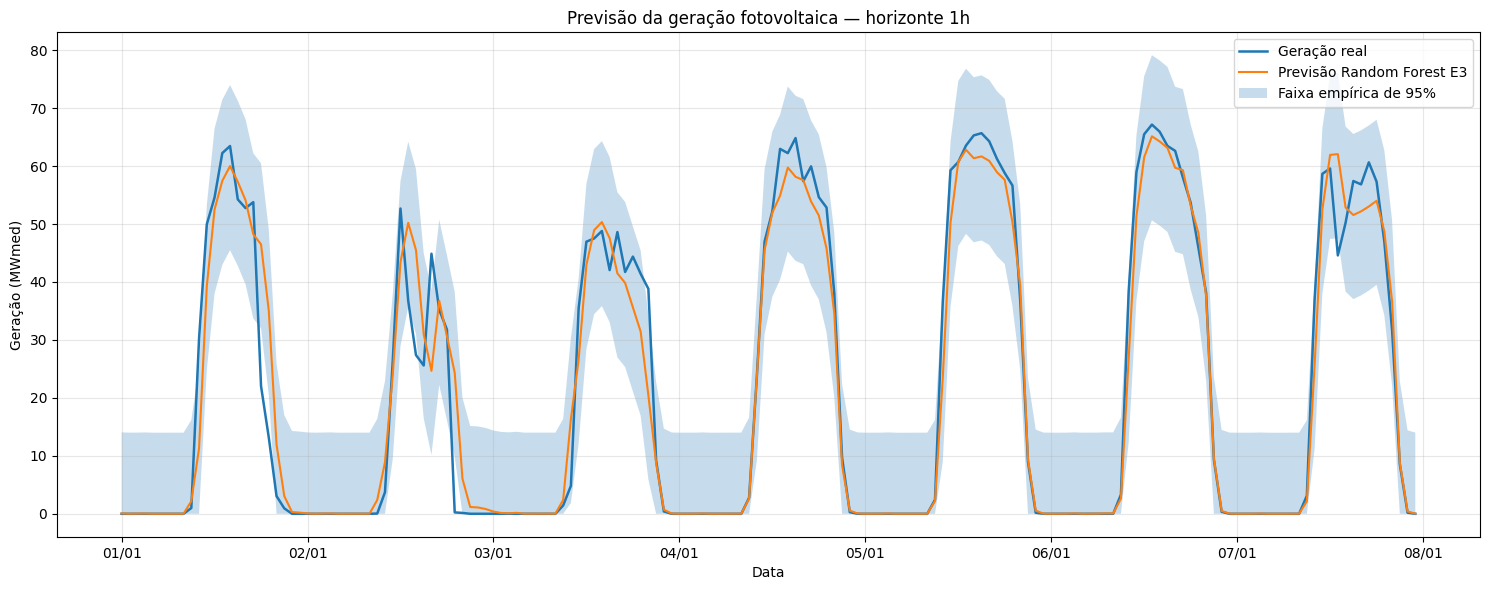

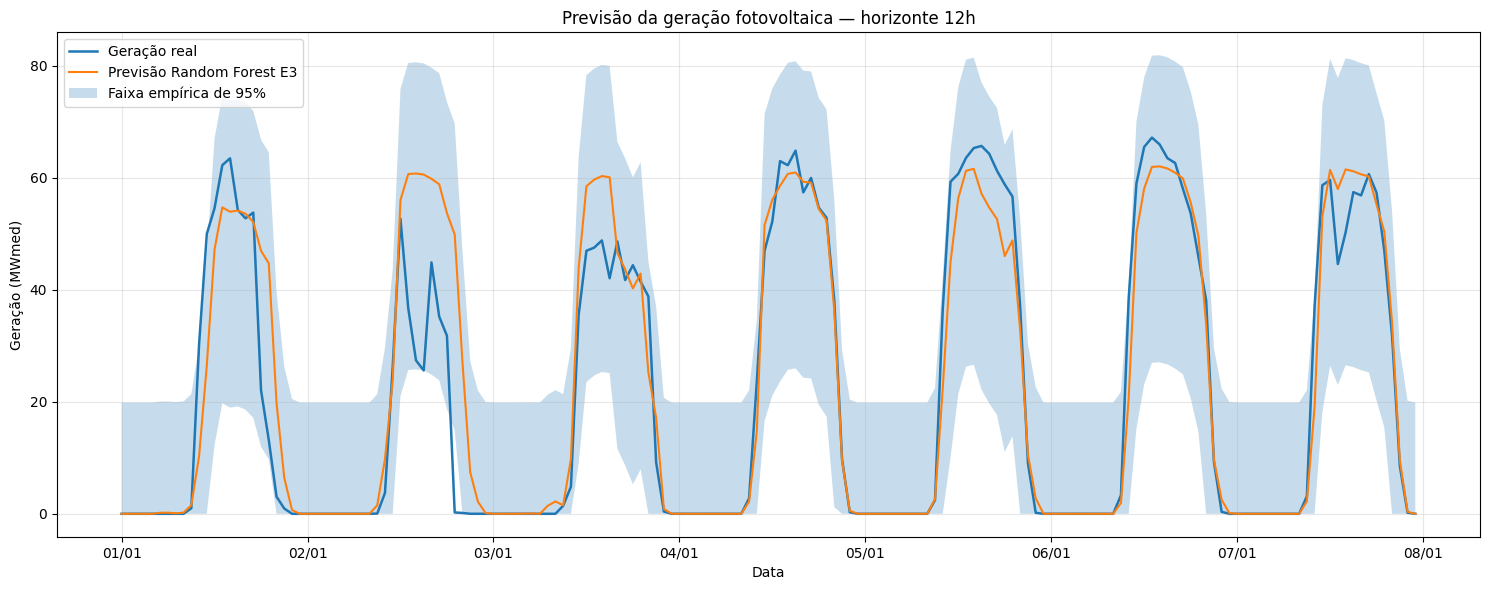

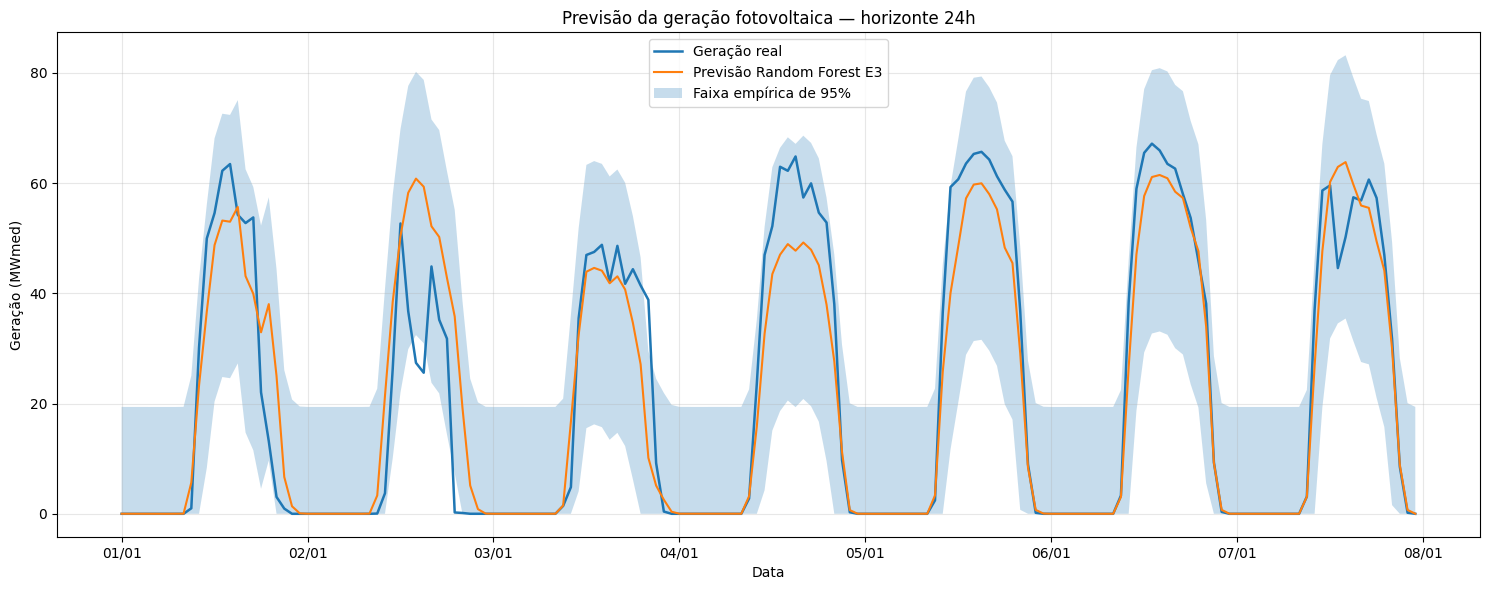

In [ ]:
inicio = pd.Timestamp('2026-01-01 00:00:00')
fim = inicio + pd.Timedelta(days=7)

for h in [1, 12, 24]:

    df_plot = intervalos_teste[h].copy()

    df_plot = df_plot[
        (df_plot['target_datetime'] >= inicio) &
        (df_plot['target_datetime'] < fim)
    ]

    plt.figure(figsize=(15, 6))

    # Valor real
    plt.plot(
        df_plot['target_datetime'],
        df_plot['real'],
        label='Geração real',
        linewidth=1.8
    )

    # Previsão
    plt.plot(
        df_plot['target_datetime'],
        df_plot['previsto'],
        label='Previsão Random Forest E3',
        linewidth=1.5
    )

    # Envelope de incerteza
    plt.fill_between(
        df_plot['target_datetime'],
        df_plot['limite_inferior'],
        df_plot['limite_superior'],
        alpha=0.25,
        label='Faixa empírica de 95%'
    )

    plt.title(
        f'Previsão da geração fotovoltaica — horizonte {h}h'
    )

    plt.xlabel('Data')
    plt.ylabel('Geração (MWmed)')

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.gca().xaxis.set_major_formatter(
        mdates.DateFormatter('%d/%m')
    )

    plt.tight_layout()
    plt.show()

In [ ]:
faixas_potencia = [0, 5, 20, 40, 60, np.inf]

nomes_faixas = [
    '0-5',
    '5-20',
    '20-40',
    '40-60',
    '60+'
]

intervalos_condicionados = {}
resumo_faixas = []

for h in [1, 12, 24]:

    experimento = 'E3'

    # ======================================
    # 1. VALIDAÇÃO
    # ======================================
    modelo_calibracao = (
        resultados_grid_rf[h][experimento]
        .best_estimator_
    )

    dados = dados_modelagem[h][experimento]

    X_val = dados['X_val']
    y_val = dados['y_val'].to_numpy()

    y_pred_val = modelo_calibracao.predict(X_val)

    residuos_val = y_val - y_pred_val

    df_calibracao = pd.DataFrame({
        'previsto': y_pred_val,
        'residuo': residuos_val
    })

    df_calibracao['faixa'] = pd.cut(
        df_calibracao['previsto'],
        bins=faixas_potencia,
        labels=nomes_faixas,
        include_lowest=True,
        right=False
    )

    # Quantis globais como fallback
    q_global_inf = np.quantile(residuos_val, 0.025)
    q_global_sup = np.quantile(residuos_val, 0.975)

    quantis_por_faixa = {}

    for faixa in nomes_faixas:

        residuos_faixa = df_calibracao.loc[
            df_calibracao['faixa'] == faixa,
            'residuo'
        ]

        # Evita calcular quantis pouco confiáveis
        # quando houver poucas observações
        if len(residuos_faixa) >= 30:
            q_inf = np.quantile(residuos_faixa, 0.025)
            q_sup = np.quantile(residuos_faixa, 0.975)
        else:
            q_inf = q_global_inf
            q_sup = q_global_sup

        quantis_por_faixa[faixa] = {
            'q_inf': q_inf,
            'q_sup': q_sup,
            'n': len(residuos_faixa)
        }

        resumo_faixas.append({
            'horizonte': h,
            'faixa': faixa,
            'n_validacao': len(residuos_faixa),
            'q_2.5': q_inf,
            'q_97.5': q_sup
        })

    # ======================================
    # 2. TESTE
    # ======================================
    modelo_final = (
        modelos_finais['Random Forest'][h][experimento]
    )

    X_test = dados_finais[h][experimento]['X_test']
    y_test = dados_finais[h][experimento]['y_test'].to_numpy()

    y_pred_test = modelo_final.predict(X_test)

    datas = (
        splits_por_horizonte[h]['test']
        ['target_datetime']
        .to_numpy()
    )

    df_intervalo = pd.DataFrame({
        'target_datetime': datas,
        'real': y_test,
        'previsto': y_pred_test
    })

    df_intervalo['faixa'] = pd.cut(
        df_intervalo['previsto'],
        bins=faixas_potencia,
        labels=nomes_faixas,
        include_lowest=True,
        right=False
    )

    limites_inferiores = []
    limites_superiores = []

    for _, linha in df_intervalo.iterrows():

        faixa = str(linha['faixa'])

        q_inf = quantis_por_faixa[faixa]['q_inf']
        q_sup = quantis_por_faixa[faixa]['q_sup']

        limite_inf = linha['previsto'] + q_inf
        limite_sup = linha['previsto'] + q_sup

        # Geração não pode ser negativa
        limite_inf = max(0, limite_inf)

        limites_inferiores.append(limite_inf)
        limites_superiores.append(limite_sup)

    df_intervalo['limite_inferior'] = limites_inferiores
    df_intervalo['limite_superior'] = limites_superiores

    intervalos_condicionados[h] = df_intervalo


df_resumo_faixas = pd.DataFrame(resumo_faixas)

df_resumo_faixas.round(3)

,horizonte,faixa,n_validacao,q_2.5,q_97.5
0,1,0-5,800,-1.942,2.487
1,1,5-20,138,-13.579,11.271
2,1,20-40,188,-18.438,22.379
3,1,40-60,331,-17.899,14.027
4,1,60+,7,-14.506,13.983
5,12,0-5,781,-1.356,2.717
6,12,5-20,115,-13.080,21.070
7,12,20-40,197,-30.746,29.948
8,12,40-60,371,-46.591,14.969
9,12,60+,0,-34.969,19.844


In [ ]:
resumo_condicionado = []

for h in [1, 12, 24]:

    df = intervalos_condicionados[h]

    cobertura = np.mean(
        (df['real'] >= df['limite_inferior']) &
        (df['real'] <= df['limite_superior'])
    ) * 100

    largura_media = np.mean(
        df['limite_superior']
        - df['limite_inferior']
    )

    resumo_condicionado.append({
        'horizonte': h,
        'largura_media': largura_media,
        'cobertura_teste_%': cobertura
    })

df_resumo_condicionado = pd.DataFrame(
    resumo_condicionado
)

df_resumo_condicionado.round(3)

,horizonte,largura_media,cobertura_teste_%
0,1,16.015,91.156
1,12,27.089,87.657
2,24,24.985,89.937


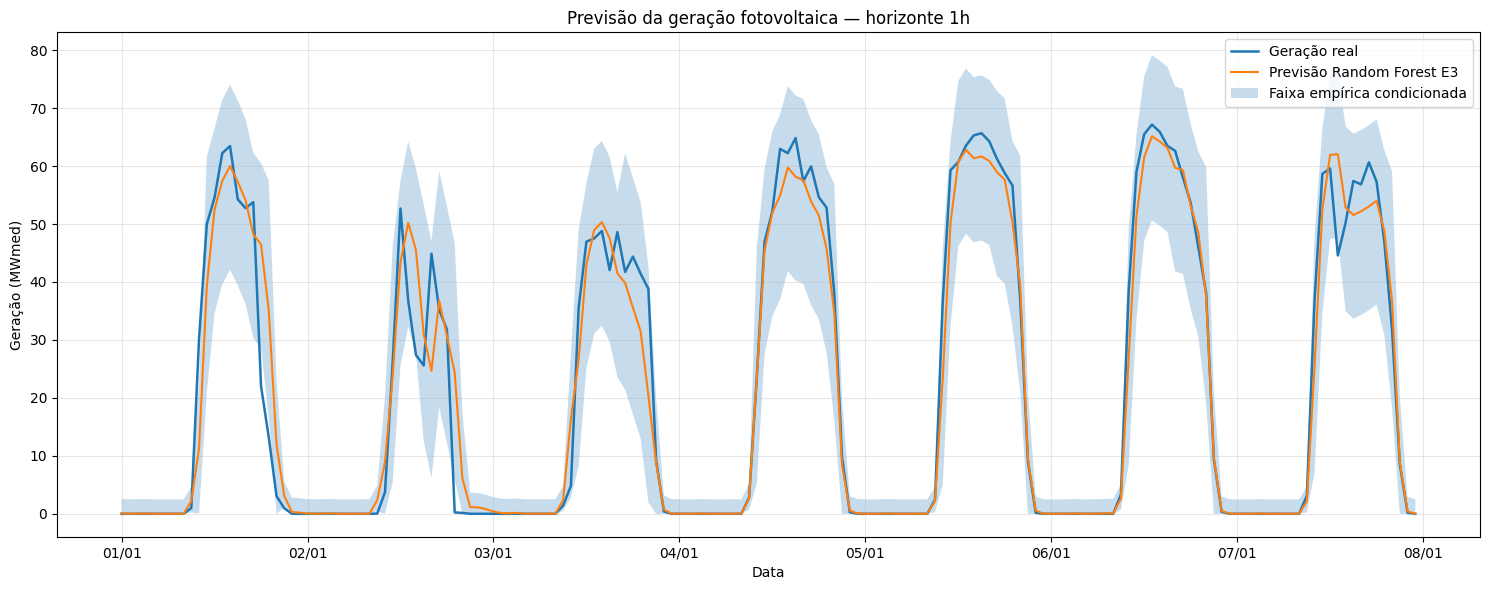

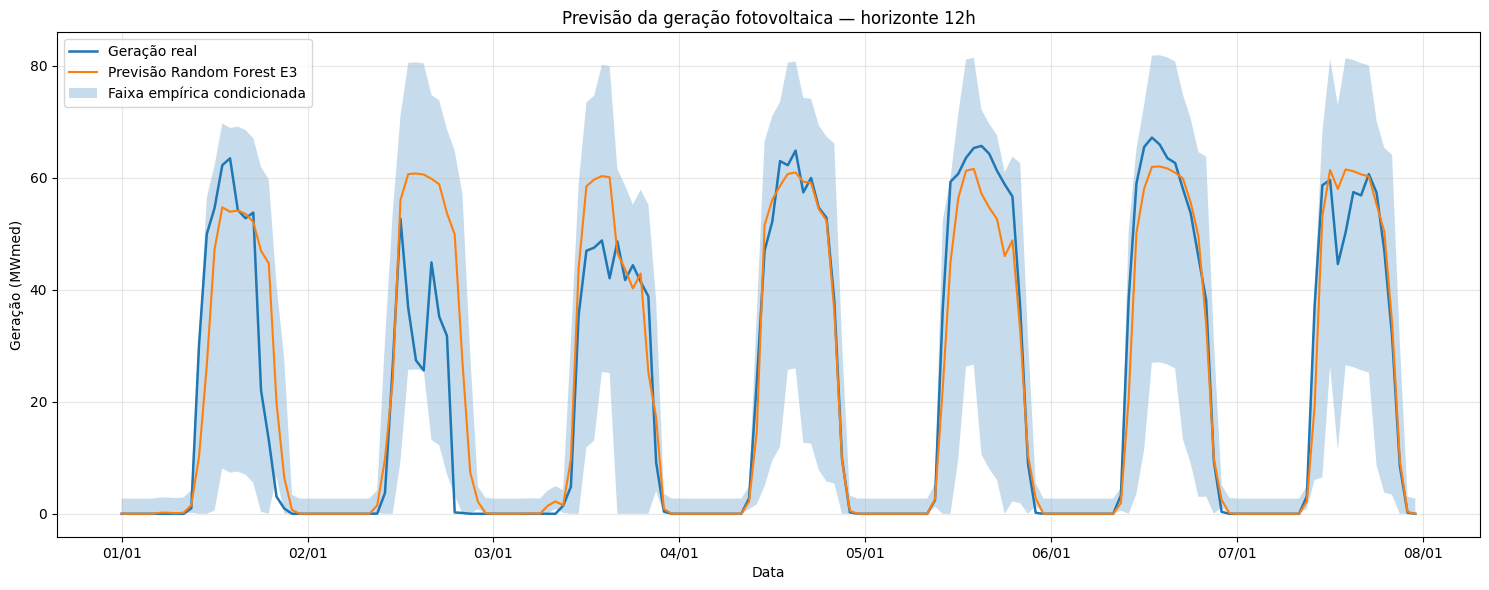

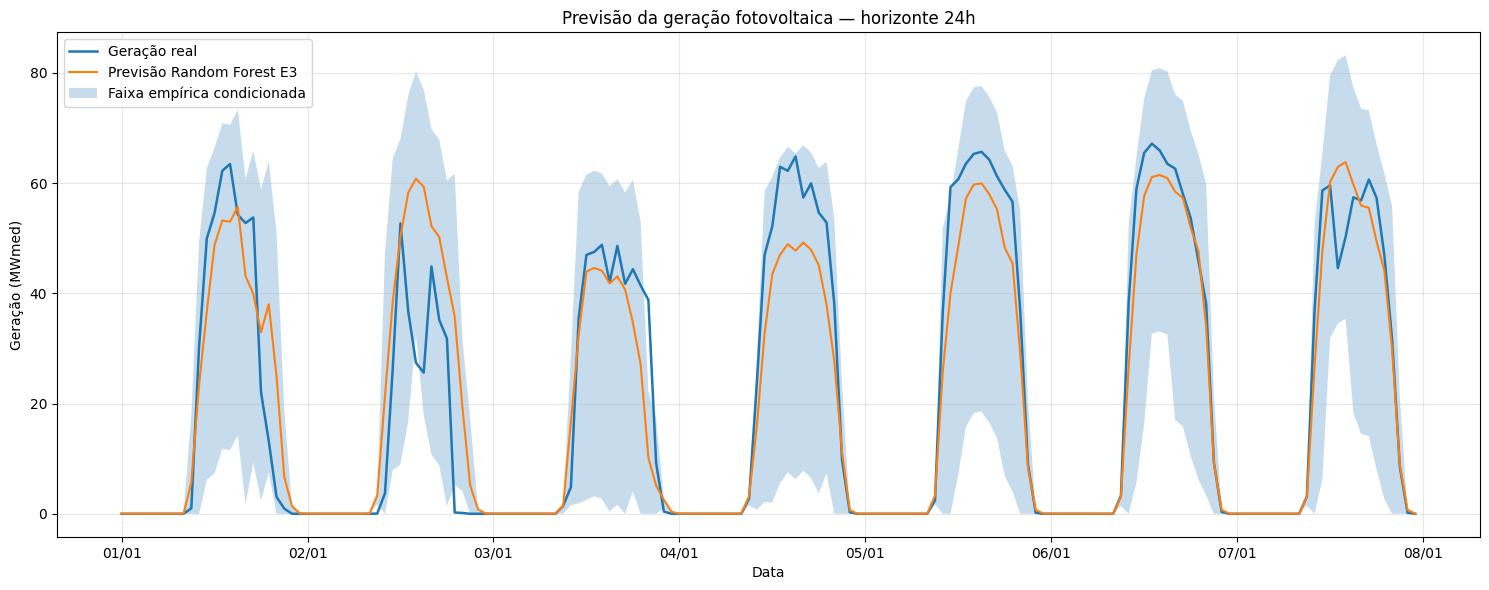

In [ ]:
inicio = pd.Timestamp('2026-01-01 00:00:00')
fim = inicio + pd.Timedelta(days=7)

for h in [1, 12, 24]:

    df_plot = intervalos_condicionados[h].copy()

    df_plot = df_plot[
        (df_plot['target_datetime'] >= inicio) &
        (df_plot['target_datetime'] < fim)
    ]

    plt.figure(figsize=(15, 6))

    plt.plot(
        df_plot['target_datetime'],
        df_plot['real'],
        label='Geração real',
        linewidth=1.8
    )

    plt.plot(
        df_plot['target_datetime'],
        df_plot['previsto'],
        label='Previsão Random Forest E3',
        linewidth=1.5
    )

    plt.fill_between(
        df_plot['target_datetime'],
        df_plot['limite_inferior'],
        df_plot['limite_superior'],
        alpha=0.25,
        label='Faixa empírica condicionada'
    )

    plt.title(
        f'Previsão da geração fotovoltaica — horizonte {h}h'
    )

    plt.xlabel('Data')
    plt.ylabel('Geração (MWmed)')

    plt.legend()
    plt.grid(alpha=0.3)

    plt.gca().xaxis.set_major_formatter(
        mdates.DateFormatter('%d/%m')
    )

    plt.tight_layout()
    plt.show()

##### Verificar um terceiro gráfico para 12 24

In [ ]:
faixas_potencia_v3 = [0, 5, 20, 40, np.inf]

nomes_faixas_v3 = [
    '0-5',
    '5-20',
    '20-40',
    '40+'
]

intervalos_v3 = {}
resumo_faixas_v3 = []

for h in [1, 12, 24]:

    experimento = 'E3'

    # ==========================================
    # 1. CALIBRAÇÃO COM A VALIDAÇÃO
    # ==========================================

    modelo_calibracao = (
        resultados_grid_rf[h][experimento]
        .best_estimator_
    )

    dados = dados_modelagem[h][experimento]

    X_val = dados['X_val']
    y_val = dados['y_val'].to_numpy()

    y_pred_val = modelo_calibracao.predict(X_val)

    residuos_val = y_val - y_pred_val

    df_calibracao = pd.DataFrame({
        'previsto': y_pred_val,
        'residuo': residuos_val
    })

    df_calibracao['faixa'] = pd.cut(
        df_calibracao['previsto'],
        bins=faixas_potencia_v3,
        labels=nomes_faixas_v3,
        include_lowest=True,
        right=False
    )

    # Quantis globais como fallback
    q_global_inf = np.quantile(
        residuos_val,
        0.025
    )

    q_global_sup = np.quantile(
        residuos_val,
        0.975
    )

    quantis_por_faixa = {}

    for faixa in nomes_faixas_v3:

        residuos_faixa = df_calibracao.loc[
            df_calibracao['faixa'] == faixa,
            'residuo'
        ]

        n = len(residuos_faixa)

        # Exigir pelo menos 100 observações
        # para utilizar os quantis específicos da faixa
        if n >= 100:

            q_inf = np.quantile(
                residuos_faixa,
                0.025
            )

            q_sup = np.quantile(
                residuos_faixa,
                0.975
            )

            origem = 'faixa'

        else:

            q_inf = q_global_inf
            q_sup = q_global_sup

            origem = 'global'

        quantis_por_faixa[faixa] = {
            'q_inf': q_inf,
            'q_sup': q_sup,
            'n': n
        }

        resumo_faixas_v3.append({
            'horizonte': h,
            'faixa': faixa,
            'n_validacao': n,
            'q_2.5': q_inf,
            'q_97.5': q_sup,
            'origem_quantis': origem
        })

    # ==========================================
    # 2. APLICAÇÃO NO TESTE
    # ==========================================

    modelo_final = (
        modelos_finais['Random Forest'][h][experimento]
    )

    X_test = dados_finais[h][experimento]['X_test']
    y_test = dados_finais[h][experimento]['y_test'].to_numpy()

    y_pred_test = modelo_final.predict(X_test)

    datas = (
        splits_por_horizonte[h]['test']
        ['target_datetime']
        .to_numpy()
    )

    df_intervalo = pd.DataFrame({
        'target_datetime': datas,
        'real': y_test,
        'previsto': y_pred_test
    })

    df_intervalo['faixa'] = pd.cut(
        df_intervalo['previsto'],
        bins=faixas_potencia_v3,
        labels=nomes_faixas_v3,
        include_lowest=True,
        right=False
    )

    limites_inferiores = []
    limites_superiores = []

    for _, linha in df_intervalo.iterrows():

        faixa = str(linha['faixa'])

        q_inf = quantis_por_faixa[faixa]['q_inf']
        q_sup = quantis_por_faixa[faixa]['q_sup']

        limite_inf = (
            linha['previsto'] + q_inf
        )

        limite_sup = (
            linha['previsto'] + q_sup
        )

        # Geração não pode ser negativa
        limite_inf = max(
            0,
            limite_inf
        )

        limites_inferiores.append(
            limite_inf
        )

        limites_superiores.append(
            limite_sup
        )

    df_intervalo['limite_inferior'] = (
        limites_inferiores
    )

    df_intervalo['limite_superior'] = (
        limites_superiores
    )

    intervalos_v3[h] = df_intervalo


df_resumo_faixas_v3 = pd.DataFrame(
    resumo_faixas_v3
)

df_resumo_faixas_v3.round(3)

,horizonte,faixa,n_validacao,q_2.5,q_97.5,origem_quantis
0,1,0-5,800,-1.942,2.487,faixa
1,1,5-20,138,-13.579,11.271,faixa
2,1,20-40,188,-18.438,22.379,faixa
3,1,40+,338,-17.874,13.991,faixa
4,12,0-5,781,-1.356,2.717,faixa
5,12,5-20,115,-13.080,21.070,faixa
6,12,20-40,197,-30.746,29.948,faixa
7,12,40+,371,-46.591,14.969,faixa
8,24,0-5,788,-1.637,0.089,faixa
9,24,5-20,109,-15.150,12.191,faixa


In [ ]:
resumo_v3 = []

for h in [1, 12, 24]:

    df = intervalos_v3[h]

    dentro_intervalo = (
        (df['real'] >= df['limite_inferior']) &
        (df['real'] <= df['limite_superior'])
    )

    cobertura = (
        dentro_intervalo.mean() * 100
    )

    largura = (
        df['limite_superior']
        - df['limite_inferior']
    )

    resumo_v3.append({
        'horizonte': h,
        'largura_media': largura.mean(),
        'largura_mediana': largura.median(),
        'cobertura_teste_%': cobertura
    })

df_resumo_v3 = pd.DataFrame(
    resumo_v3
)

df_resumo_v3.round(3)

,horizonte,largura_media,largura_mediana,cobertura_teste_%
0,1,16.185,4.430,91.234
1,12,27.131,4.073,87.677
2,24,25.036,1.727,89.996


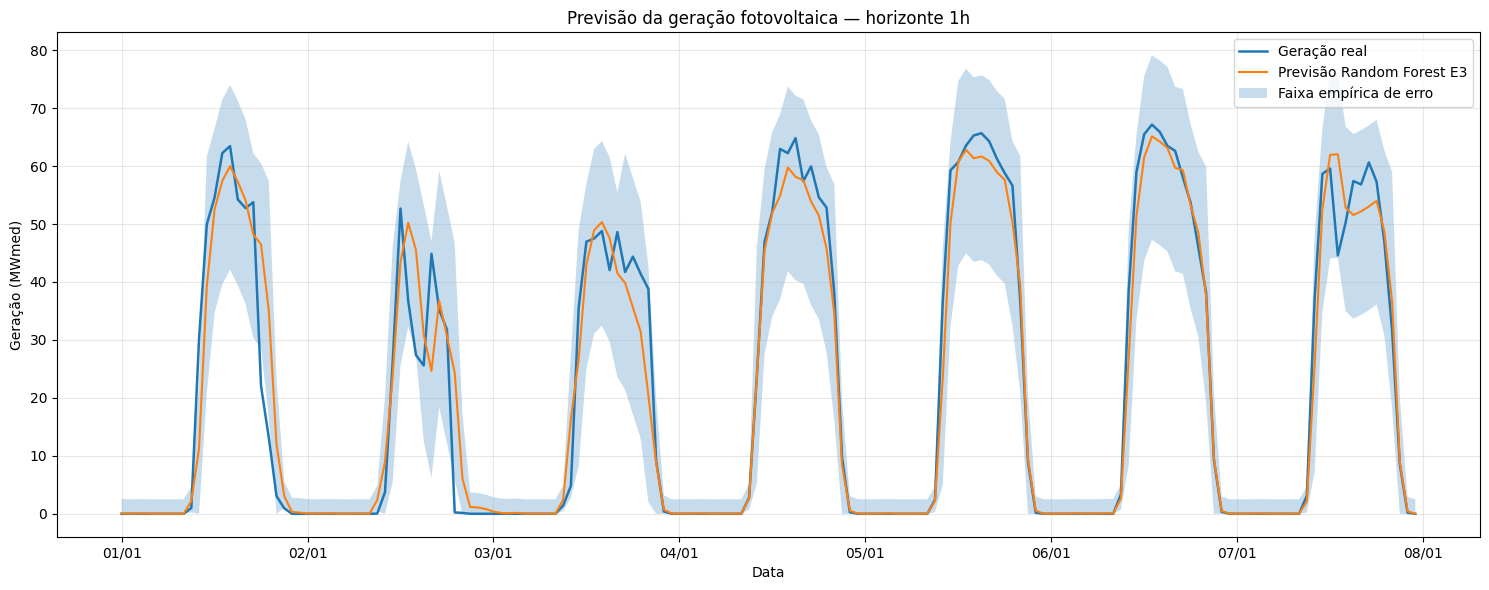

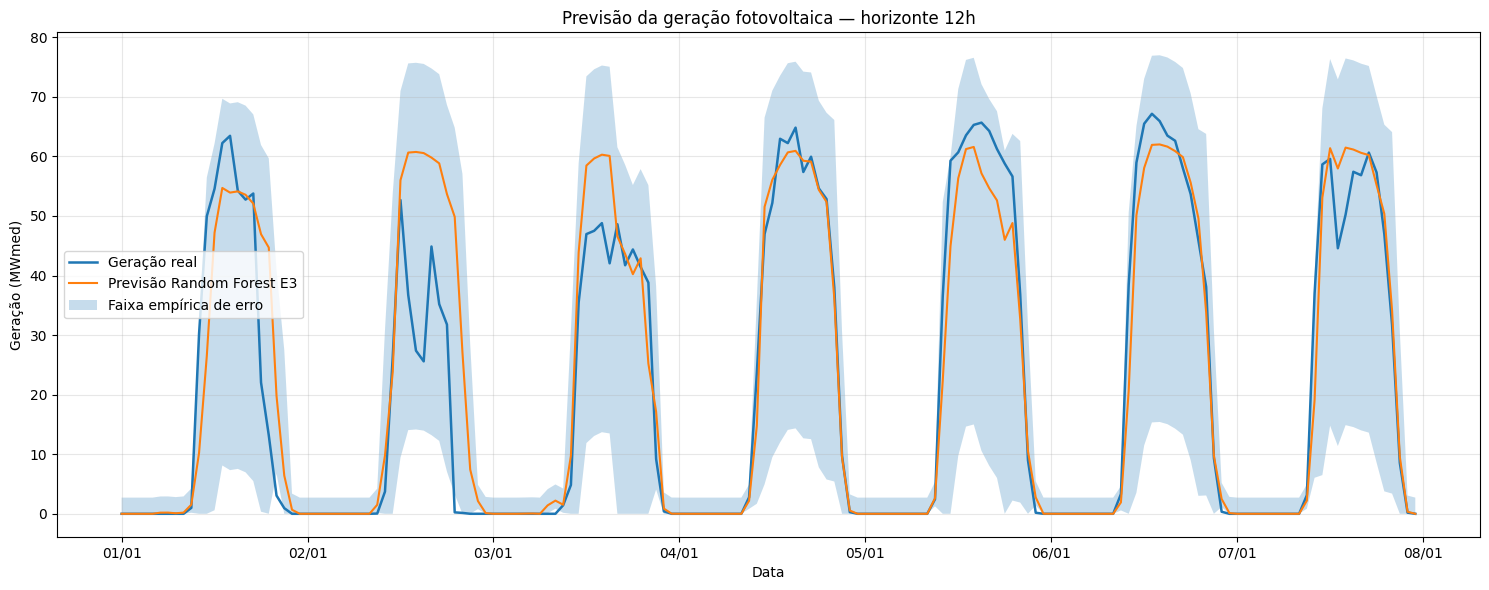

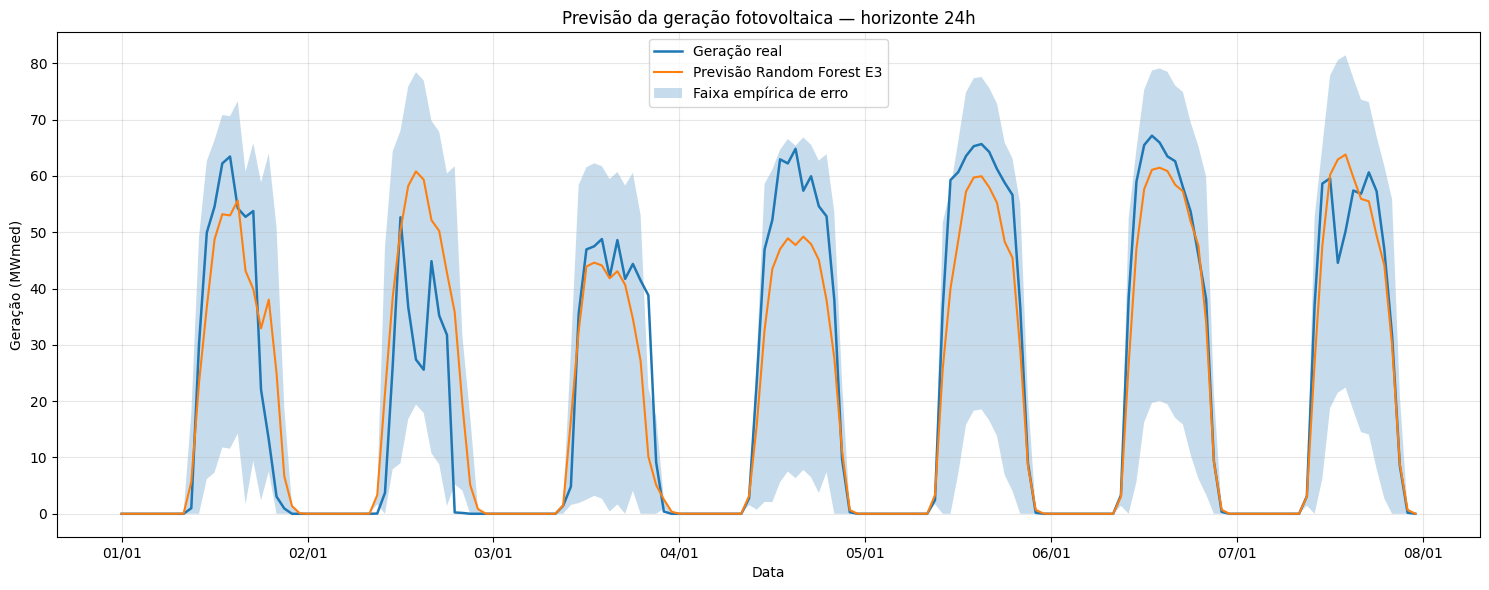

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

inicio = pd.Timestamp(
    '2026-01-01 00:00:00'
)

fim = inicio + pd.Timedelta(
    days=7
)

for h in [1, 12, 24]:

    df_plot = intervalos_v3[h].copy()

    df_plot = df_plot[
        (df_plot['target_datetime'] >= inicio) &
        (df_plot['target_datetime'] < fim)
    ]

    plt.figure(
        figsize=(15, 6)
    )

    # Geração observada
    plt.plot(
        df_plot['target_datetime'],
        df_plot['real'],
        label='Geração real',
        linewidth=1.8
    )

    # Previsão
    plt.plot(
        df_plot['target_datetime'],
        df_plot['previsto'],
        label='Previsão Random Forest E3',
        linewidth=1.5
    )

    # Faixa empírica
    plt.fill_between(
        df_plot['target_datetime'],
        df_plot['limite_inferior'],
        df_plot['limite_superior'],
        alpha=0.25,
        label='Faixa empírica de erro'
    )

    plt.title(
        f'Previsão da geração fotovoltaica — horizonte {h}h'
    )

    plt.xlabel('Data')

    plt.ylabel(
        'Geração (MWmed)'
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.gca().xaxis.set_major_formatter(
        mdates.DateFormatter('%d/%m')
    )

    plt.tight_layout()

    plt.show()

In [ ]:
comparacao_intervalos = pd.DataFrame({
    'horizonte': [1, 12, 24],

    'largura_global': [
        20.491,
        33.934,
        31.671
    ],

    'cobertura_global_%': [
        91.627,
        92.020,
        90.782
    ],

    'largura_v2': [
        16.015,
        27.089,
        24.985
    ],

    'cobertura_v2_%': [
        91.156,
        87.657,
        89.937
    ]
})

comparacao_intervalos = comparacao_intervalos.merge(
    df_resumo_v3[
        [
            'horizonte',
            'largura_media',
            'cobertura_teste_%'
        ]
    ],
    on='horizonte'
)

comparacao_intervalos = comparacao_intervalos.rename(
    columns={
        'largura_media': 'largura_v3',
        'cobertura_teste_%': 'cobertura_v3_%'
    }
)

comparacao_intervalos.round(3)

,horizonte,largura_global,cobertura_global_%,largura_v2,cobertura_v2_%,largura_v3,cobertura_v3_%
0,1,20.491,91.627,16.015,91.156,16.185,91.234
1,12,33.934,92.020,27.089,87.657,27.131,87.677
2,24,31.671,90.782,24.985,89.937,25.036,89.996


### Gráfico principal: RMSE × horizonte × conjunto de atributos

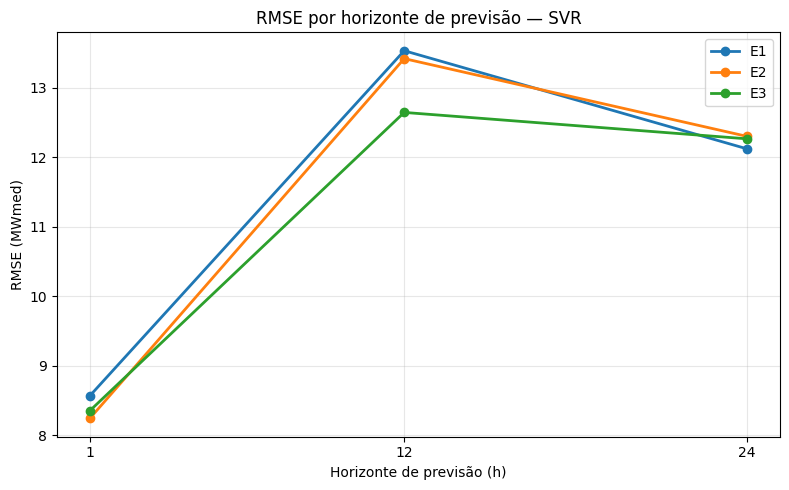

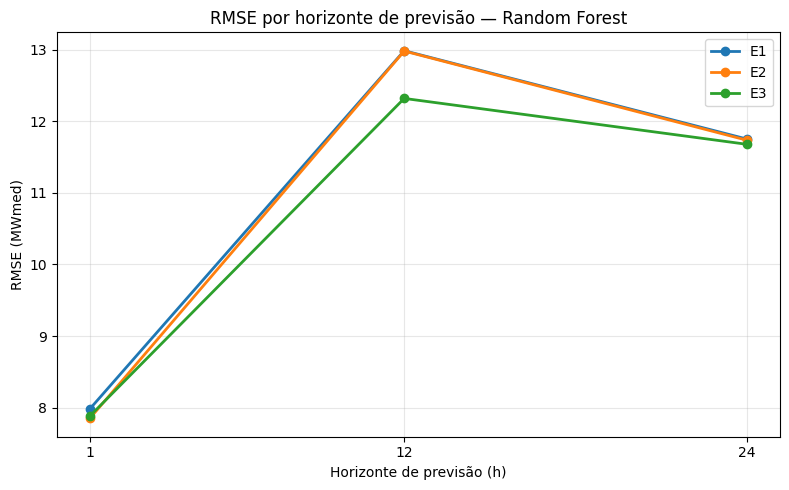

In [ ]:
for modelo in ['SVR', 'Random Forest']:

    df_plot = df_resultados_teste[
        df_resultados_teste['modelo'] == modelo
    ]

    plt.figure(figsize=(8, 5))

    for experimento in ['E1', 'E2', 'E3']:

        dados = df_plot[
            df_plot['experimento'] == experimento
        ].sort_values('horizonte')

        plt.plot(
            dados['horizonte'],
            dados['RMSE'],
            marker='o',
            linewidth=2,
            label=experimento
        )

    plt.xticks([1, 12, 24])

    plt.xlabel('Horizonte de previsão (h)')
    plt.ylabel('RMSE (MWmed)')

    plt.title(
        f'RMSE por horizonte de previsão — {modelo}'
    )

    plt.grid(alpha=0.3)
    plt.legend()

    plt.tight_layout()
    plt.show()

### Modelos × baselines

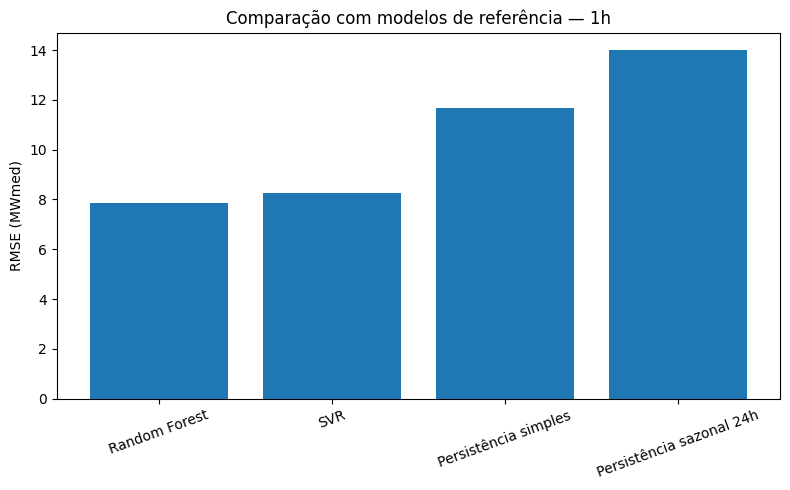

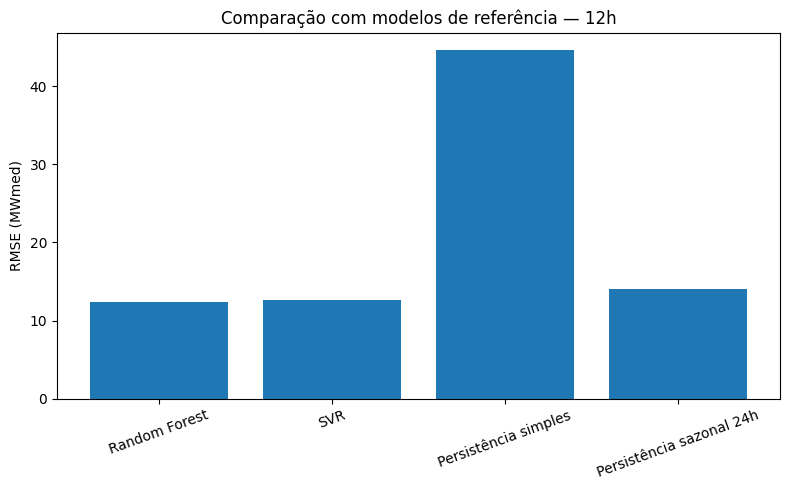

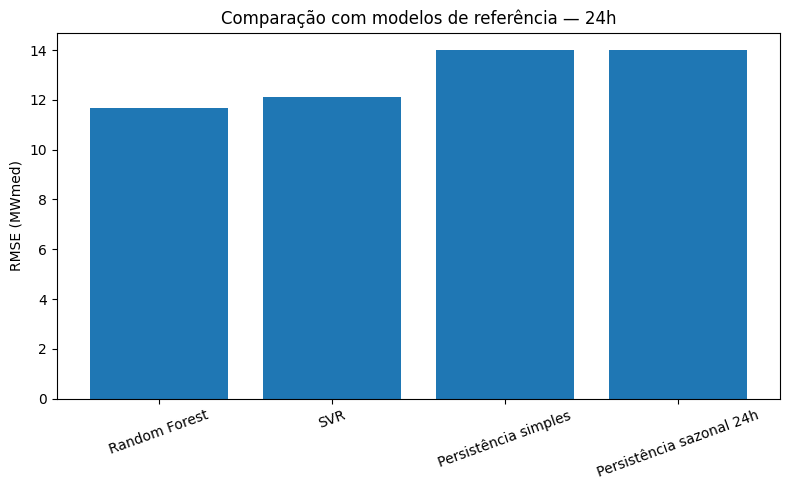

In [ ]:
melhores_ml = (
    df_resultados_teste
    .sort_values('RMSE')
    .groupby(
        ['horizonte', 'modelo'],
        as_index=False
    )
    .first()
)

baselines = df_baselines_teste.copy()

df_comparacao_modelos = pd.concat([
    melhores_ml[
        ['horizonte', 'modelo', 'RMSE']
    ],
    baselines[
        ['horizonte', 'modelo', 'RMSE']
    ]
])

for h in [1, 12, 24]:

    dados = df_comparacao_modelos[
        df_comparacao_modelos['horizonte'] == h
    ]

    plt.figure(figsize=(8, 5))

    plt.bar(
        dados['modelo'],
        dados['RMSE']
    )

    plt.ylabel('RMSE (MWmed)')
    plt.title(
        f'Comparação com modelos de referência — {h}h'
    )

    plt.xticks(rotation=20)

    plt.tight_layout()
    plt.show()

### Permutation Importance do Random Forest

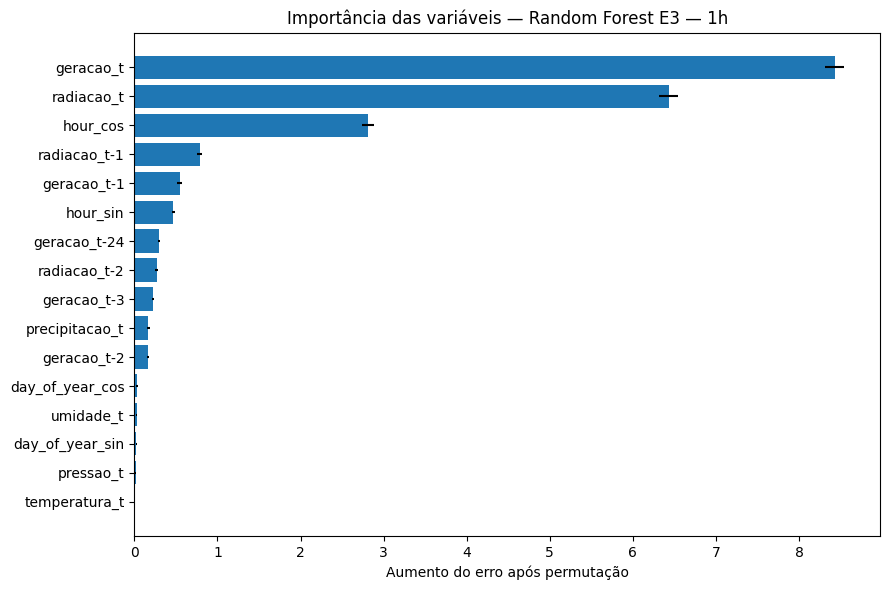

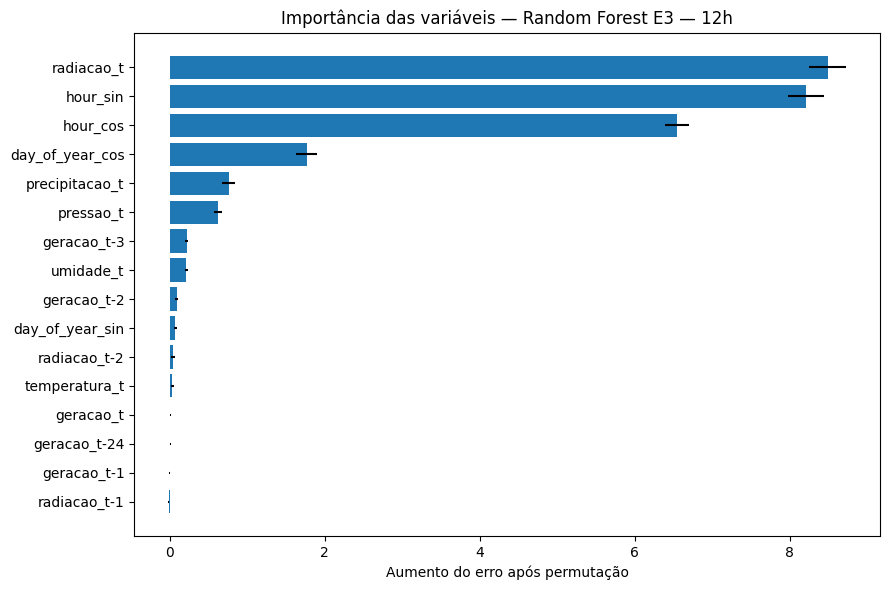

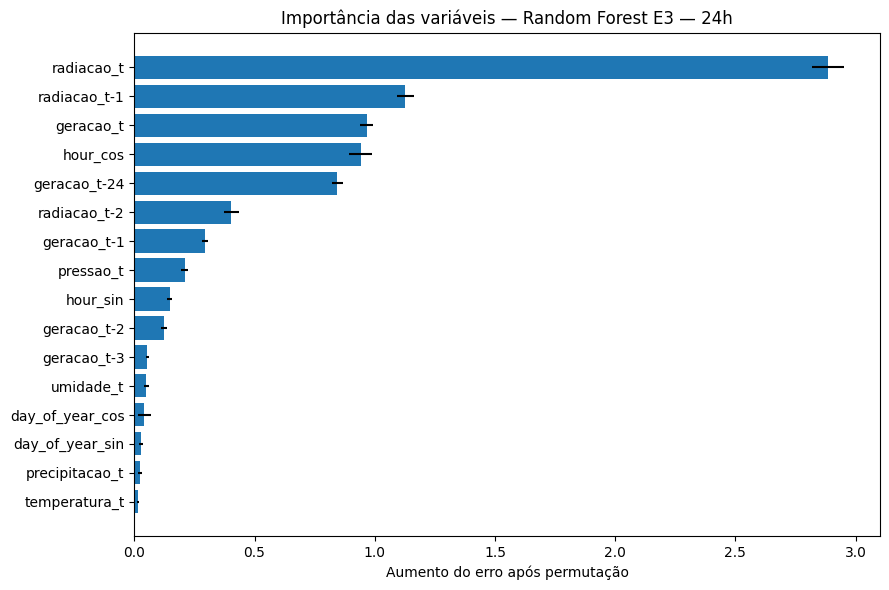

In [ ]:
from sklearn.inspection import permutation_importance

importancias = {}

for h in [1, 12, 24]:

    experimento = 'E3'

    modelo = (
        modelos_finais['Random Forest']
        [h][experimento]
    )

    X_test = dados_finais[h][experimento]['X_test']
    y_test = dados_finais[h][experimento]['y_test']

    resultado = permutation_importance(
        modelo,
        X_test,
        y_test,
        n_repeats=10,
        random_state=42,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1
    )

    df_imp = pd.DataFrame({
        'feature': X_test.columns,
        'importance': resultado.importances_mean,
        'std': resultado.importances_std
    }).sort_values(
        'importance',
        ascending=True
    )

    importancias[h] = df_imp

    plt.figure(figsize=(9, 6))

    plt.barh(
        df_imp['feature'],
        df_imp['importance'],
        xerr=df_imp['std']
    )

    plt.xlabel(
        'Aumento do erro após permutação'
    )

    plt.title(
        f'Importância das variáveis — Random Forest E3 — {h}h'
    )

    plt.tight_layout()
    plt.show()

### Salvar testes feitos

In [ ]:
df_validacao_completa.to_csv('df_validacao_completa.csv', index=False)

In [ ]:
df_resultados_teste.to_csv('df_resultados_teste.csv', index=False)

In [ ]:
df_teste_completo.to_csv('df_teste_completo.csv', index=False)

In [ ]:
df_comparacao_features.to_csv('df_comparacao_features.csv', index=False)

In [ ]:
df_comparacao_horizontes.to_csv('df_comparacao_horizontes.csv', index=False)

In [ ]:
df_resumo_v3.to_csv('df_resumo_v3.csv', index=False)

In [ ]:
df_resumo_faixas_v3.to_csv('df_resumo_faixas_v3.csv', index=False)

##

In [38]:
df_validacao_completa = pd.read_csv('/content/df_validacao_completa.csv')

## XGBoost

In [23]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

In [24]:
xgb_model = XGBRegressor(
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

In [25]:
param_grid_xgb = {
    'n_estimators': [200, 500],
    'max_depth': [3, 6],
    'learning_rate': [0.03, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

In [26]:
def tunar_xgb(h, experimento):
    dados = dados_modelagem[h][experimento]

    X_train = dados['X_train']
    y_train = dados['y_train']

    tscv = TimeSeriesSplit(
        n_splits=5,
        gap=h
    )

    grid = GridSearchCV(
        estimator=xgb_model,
        param_grid=param_grid_xgb,
        scoring='neg_root_mean_squared_error',
        cv=tscv,
        n_jobs=-1,
        verbose=1
    )

    grid.fit(
        X_train,
        y_train
    )

    return grid

In [27]:
grid_xgb_h1_e1 = tunar_xgb(
    1,
    'E1'
)

print('Melhores parâmetros:')
print(
    grid_xgb_h1_e1.best_params_
)

print('\nMelhor RMSE médio no CV:')
print(
    -grid_xgb_h1_e1.best_score_
)

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Melhores parâmetros:
{'colsample_bytree': 1.0, 'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}

Melhor RMSE médio no CV:
6.340055946629989


In [28]:
resultados_grid_xgb = {
    1: {},
    12: {},
    24: {}
}

resultados_grid_xgb[1]['E1'] = grid_xgb_h1_e1

for h in [1, 12, 24]:
    for experimento in ['E1', 'E2', 'E3']:

        if h == 1 and experimento == 'E1':
            continue

        print(
            f'\n===== XGBoost | Horizonte {h}h | {experimento} ====='
        )

        grid = tunar_xgb(
            h,
            experimento
        )

        resultados_grid_xgb[h][experimento] = grid

        print('Melhores parâmetros:')
        print(grid.best_params_)

        print('RMSE médio CV:')
        print(-grid.best_score_)


===== XGBoost | Horizonte 1h | E2 =====
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Melhores parâmetros:
{'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}
RMSE médio CV:
6.1568421988951245

===== XGBoost | Horizonte 1h | E3 =====
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Melhores parâmetros:
{'colsample_bytree': 1.0, 'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}
RMSE médio CV:
6.259000917731226

===== XGBoost | Horizonte 12h | E1 =====
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Melhores parâmetros:
{'colsample_bytree': 1.0, 'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}
RMSE médio CV:
10.76301907766209

===== XGBoost | Horizonte 12h | E2 =====
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Melhores parâmetros:
{'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200, 'sub

In [29]:
resumo_xgb_cv = []

for h in [1, 12, 24]:
    for experimento in ['E1', 'E2', 'E3']:

        grid = resultados_grid_xgb[h][experimento]

        params = grid.best_params_

        resumo_xgb_cv.append({
            'horizonte': h,
            'experimento': experimento,
            'n_estimators': params['n_estimators'],
            'max_depth': params['max_depth'],
            'learning_rate': params['learning_rate'],
            'subsample': params['subsample'],
            'colsample_bytree': params['colsample_bytree'],
            'RMSE_CV': -grid.best_score_
        })

df_resumo_xgb_cv = pd.DataFrame(
    resumo_xgb_cv
)

df_resumo_xgb_cv

,horizonte,experimento,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,RMSE_CV
0,1,E1,200,3,0.03,0.8,1.0,6.340056
1,1,E2,200,3,0.03,0.8,0.8,6.156842
2,1,E3,200,3,0.03,0.8,1.0,6.259001
3,12,E1,200,3,0.03,0.8,1.0,10.763019
4,12,E2,200,3,0.03,0.8,0.8,10.842128
5,12,E3,200,6,0.03,0.8,1.0,10.769034
6,24,E1,200,3,0.03,0.8,0.8,10.218949
7,24,E2,200,3,0.03,1.0,1.0,10.039048
8,24,E3,200,3,0.03,0.8,1.0,10.053249


#### Testar com um Grid Refinado diferente

In [30]:
param_grid_xgb_refinado = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 6],
    'learning_rate': [0.01, 0.03, 0.05],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

In [31]:
def tunar_xgb_refinado(h, experimento):
    dados = dados_modelagem[h][experimento]

    X_train = dados['X_train']
    y_train = dados['y_train']

    tscv = TimeSeriesSplit(
        n_splits=5,
        gap=h
    )

    grid = GridSearchCV(
        estimator=xgb_model,
        param_grid=param_grid_xgb_refinado,
        scoring='neg_root_mean_squared_error',
        cv=tscv,
        n_jobs=-1,
        verbose=1
    )

    grid.fit(
        X_train,
        y_train
    )

    return grid

In [32]:
grid_xgb_refinado_h1_e2 = tunar_xgb_refinado(
    1,
    'E2'
)

print(grid_xgb_refinado_h1_e2.best_params_)
print(
    -grid_xgb_refinado_h1_e2.best_score_
)

Fitting 5 folds for each of 72 candidates, totalling 360 fits
{'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}
6.1568421988951245


In [33]:
resultados_grid_xgb_refinado = {
    1: {},
    12: {},
    24: {}
}

resultados_grid_xgb_refinado[1]['E2'] = grid_xgb_refinado_h1_e2

for h in [1, 12, 24]:
    for experimento in ['E1', 'E2', 'E3']:

        if h == 1 and experimento == 'E2':
            continue

        print(
            f'\n===== XGBoost | Horizonte {h}h | {experimento} ====='
        )

        grid = tunar_xgb_refinado(
            h,
            experimento
        )

        resultados_grid_xgb_refinado[h][experimento] = grid

        print('Melhores parâmetros:')
        print(grid.best_params_)

        print('RMSE médio CV:')
        print(-grid.best_score_)


===== XGBoost | Horizonte 1h | E1 =====
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Melhores parâmetros:
{'colsample_bytree': 1.0, 'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}
RMSE médio CV:
6.340055946629989

===== XGBoost | Horizonte 1h | E3 =====
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Melhores parâmetros:
{'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
RMSE médio CV:
6.2104908417380695

===== XGBoost | Horizonte 12h | E1 =====
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Melhores parâmetros:
{'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 6, 'n_estimators': 100, 'subsample': 1.0}
RMSE médio CV:
10.47897282016633

===== XGBoost | Horizonte 12h | E2 =====
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Melhores parâmetros:
{'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 6, 'n_estimators': 300, 'sub

In [34]:
resumo_xgb_cv_refinado = []

for h in [1, 12, 24]:
    for experimento in ['E1', 'E2', 'E3']:

        grid = resultados_grid_xgb_refinado[h][experimento]

        params = grid.best_params_

        resumo_xgb_cv_refinado.append({
            'horizonte': h,
            'experimento': experimento,
            'n_estimators': params['n_estimators'],
            'max_depth': params['max_depth'],
            'learning_rate': params['learning_rate'],
            'subsample': params['subsample'],
            'colsample_bytree': params['colsample_bytree'],
            'RMSE_CV': -grid.best_score_
        })

df_resumo_xgb_cv_refinado = pd.DataFrame(
    resumo_xgb_cv_refinado
)

df_resumo_xgb_cv_refinado

,horizonte,experimento,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,RMSE_CV
0,1,E1,200,3,0.03,0.8,1.0,6.340056
1,1,E2,200,3,0.03,0.8,0.8,6.156842
2,1,E3,100,3,0.05,0.8,0.8,6.210491
3,12,E1,100,6,0.03,1.0,0.8,10.478973
4,12,E2,300,6,0.01,0.8,0.8,10.799204
5,12,E3,100,6,0.03,0.8,1.0,10.563938
6,24,E1,100,3,0.05,0.8,0.8,10.132924
7,24,E2,300,3,0.01,1.0,1.0,9.956073
8,24,E3,100,3,0.05,1.0,0.8,9.917796


Prosseguindo com o grid refinado

In [35]:
resultados_validacao_xgb = []

for h in [1, 12, 24]:
    for experimento in ['E1', 'E2', 'E3']:

        grid = resultados_grid_xgb_refinado[h][experimento]

        modelo = grid.best_estimator_

        dados = dados_modelagem[h][experimento]

        X_val = dados['X_val']
        y_val = dados['y_val']

        y_pred = modelo.predict(X_val)

        mae = mean_absolute_error(
            y_val,
            y_pred
        )

        rmse = mean_squared_error(
            y_val,
            y_pred
        ) ** 0.5

        r2 = r2_score(
            y_val,
            y_pred
        )

        resultados_validacao_xgb.append({
            'horizonte': h,
            'modelo': 'XGBoost',
            'experimento': experimento,
            'MAE': mae,
            'RMSE': rmse,
            'R2': r2
        })

df_validacao_xgb = pd.DataFrame(
    resultados_validacao_xgb
)

df_validacao_xgb

,horizonte,modelo,experimento,MAE,RMSE,R2
0,1,XGBoost,E1,3.344520,6.377117,0.913527
1,1,XGBoost,E2,3.297450,6.151401,0.919540
2,1,XGBoost,E3,3.341657,6.165835,0.919162
3,12,XGBoost,E1,6.238505,11.516890,0.717964
4,12,XGBoost,E2,6.090932,11.255575,0.730618
5,12,XGBoost,E3,5.963184,10.872560,0.748640
6,24,XGBoost,E1,5.501460,10.087919,0.783610
7,24,XGBoost,E2,5.850950,10.184120,0.779464
8,24,XGBoost,E3,5.365055,10.086881,0.783655


In [36]:
df_validacao_xgb.sort_values(
    ['horizonte', 'RMSE']
)

,horizonte,modelo,experimento,MAE,RMSE,R2
1,1,XGBoost,E2,3.297450,6.151401,0.919540
2,1,XGBoost,E3,3.341657,6.165835,0.919162
0,1,XGBoost,E1,3.344520,6.377117,0.913527
5,12,XGBoost,E3,5.963184,10.872560,0.748640
4,12,XGBoost,E2,6.090932,11.255575,0.730618
3,12,XGBoost,E1,6.238505,11.516890,0.717964
8,24,XGBoost,E3,5.365055,10.086881,0.783655
6,24,XGBoost,E1,5.501460,10.087919,0.783610
7,24,XGBoost,E2,5.850950,10.184120,0.779464


In [39]:
df_validacao_com_xgb = pd.concat([
    df_validacao_completa,
    df_validacao_xgb
], ignore_index=True)

df_validacao_com_xgb.sort_values(
    ['horizonte', 'RMSE']
)

,horizonte,experimento,modelo,MAE,RMSE,R2
0,1,E3,Random Forest,3.175650,5.903518,0.925894
1,1,E2,Random Forest,3.194073,5.968373,0.924257
25,1,E2,XGBoost,3.297450,6.151401,0.919540
26,1,E3,XGBoost,3.341657,6.165835,0.919162
2,1,E1,Random Forest,3.260090,6.167926,0.919107
24,1,E1,XGBoost,3.344520,6.377117,0.913527
3,1,E1,SVR,3.440613,6.597930,0.907435
4,1,E2,SVR,3.712411,6.677261,0.905195
5,1,E3,SVR,3.737762,6.708500,0.904306
6,1,-,Persistência simples,5.217168,9.445246,0.810303


In [41]:
dados_finais = {
    1: {},
    12: {},
    24: {}
}

for h in [1, 12, 24]:
    for experimento in ['E1', 'E2', 'E3']:

        dados = dados_modelagem[h][experimento]

        X_trainval = pd.concat([
            dados['X_train'],
            dados['X_val']
        ])

        y_trainval = pd.concat([
            dados['y_train'],
            dados['y_val']
        ])

        dados_finais[h][experimento] = {
            'X_trainval': X_trainval,
            'y_trainval': y_trainval,
            'X_test': dados['X_test'],
            'y_test': dados['y_test']
        }

In [42]:
for h in [1, 12, 24]:
    for experimento in ['E1', 'E2', 'E3']:

        dados = dados_finais[h][experimento]

        print(
            h,
            experimento,
            dados['X_trainval'].shape,
            dados['X_test'].shape
        )

1 E1 (7248, 9) (5088, 9)
1 E2 (7248, 12) (5088, 12)
1 E3 (7248, 16) (5088, 16)
12 E1 (7248, 9) (5088, 9)
12 E2 (7248, 12) (5088, 12)
12 E3 (7248, 16) (5088, 16)
24 E1 (7248, 9) (5088, 9)
24 E2 (7248, 12) (5088, 12)
24 E3 (7248, 16) (5088, 16)


In [43]:
for h in [1, 12, 24]:
    for experimento in ['E1', 'E2', 'E3']:

        dados = dados_finais[h][experimento]

        print(
            h,
            experimento,
            dados['X_trainval'].shape,
            dados['X_test'].shape
        )

1 E1 (7248, 9) (5088, 9)
1 E2 (7248, 12) (5088, 12)
1 E3 (7248, 16) (5088, 16)
12 E1 (7248, 9) (5088, 9)
12 E2 (7248, 12) (5088, 12)
12 E3 (7248, 16) (5088, 16)
24 E1 (7248, 9) (5088, 9)
24 E2 (7248, 12) (5088, 12)
24 E3 (7248, 16) (5088, 16)


In [44]:
modelos_finais_xgb = {
    1: {},
    12: {},
    24: {}
}

for h in [1, 12, 24]:
    for experimento in ['E1', 'E2', 'E3']:

        print(
            f'Treinando XGBoost final | {h}h | {experimento}'
        )

        modelo = clone(
            resultados_grid_xgb_refinado[h][experimento]
            .best_estimator_
        )

        dados = dados_finais[h][experimento]

        modelo.fit(
            dados['X_trainval'],
            dados['y_trainval']
        )

        modelos_finais_xgb[h][experimento] = modelo

Treinando XGBoost final | 1h | E1
Treinando XGBoost final | 1h | E2
Treinando XGBoost final | 1h | E3
Treinando XGBoost final | 12h | E1
Treinando XGBoost final | 12h | E2
Treinando XGBoost final | 12h | E3
Treinando XGBoost final | 24h | E1
Treinando XGBoost final | 24h | E2
Treinando XGBoost final | 24h | E3


In [45]:
resultados_teste_xgb = []

for h in [1, 12, 24]:
    for experimento in ['E1', 'E2', 'E3']:

        modelo = modelos_finais_xgb[h][experimento]

        dados = dados_finais[h][experimento]

        X_test = dados['X_test']
        y_test = dados['y_test']

        y_pred = modelo.predict(X_test)

        mae = mean_absolute_error(
            y_test,
            y_pred
        )

        rmse = mean_squared_error(
            y_test,
            y_pred
        ) ** 0.5

        r2 = r2_score(
            y_test,
            y_pred
        )

        resultados_teste_xgb.append({
            'horizonte': h,
            'modelo': 'XGBoost',
            'experimento': experimento,
            'MAE': mae,
            'RMSE': rmse,
            'R2': r2
        })

df_resultados_teste_xgb = pd.DataFrame(
    resultados_teste_xgb
)

df_resultados_teste_xgb.sort_values(
    ['horizonte', 'RMSE']
)

,horizonte,modelo,experimento,MAE,RMSE,R2
1,1,XGBoost,E2,4.102307,7.885999,0.901846
2,1,XGBoost,E3,4.179450,7.921118,0.900970
0,1,XGBoost,E1,4.202200,8.062583,0.897402
5,12,XGBoost,E3,7.526005,12.576155,0.750375
4,12,XGBoost,E2,7.690629,12.859632,0.738995
3,12,XGBoost,E1,7.719596,12.911641,0.736879
8,24,XGBoost,E3,6.657545,11.658659,0.785469
6,24,XGBoost,E1,6.617857,11.756439,0.781856
7,24,XGBoost,E2,7.189531,11.930710,0.775340


In [47]:
df_resultados_teste_xgb.to_csv('df_resultados_teste_xgb.csv', index=False)

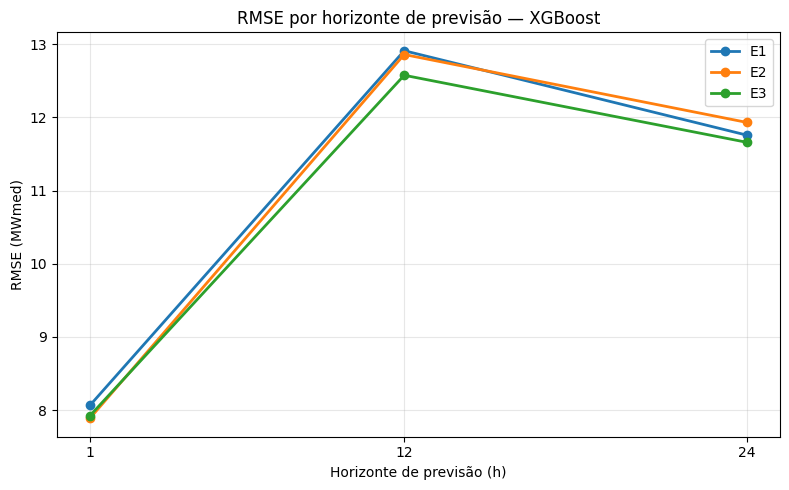

In [48]:
import matplotlib.pyplot as plt

df_plot = df_resultados_teste_xgb.copy()

plt.figure(figsize=(8, 5))

for experimento in ['E1', 'E2', 'E3']:

    dados = (
        df_plot[
            df_plot['experimento'] == experimento
        ]
        .sort_values('horizonte')
    )

    plt.plot(
        dados['horizonte'],
        dados['RMSE'],
        marker='o',
        linewidth=2,
        label=experimento
    )

plt.xticks([1, 12, 24])

plt.xlabel('Horizonte de previsão (h)')
plt.ylabel('RMSE (MWmed)')
plt.title('RMSE por horizonte de previsão — XGBoost')

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

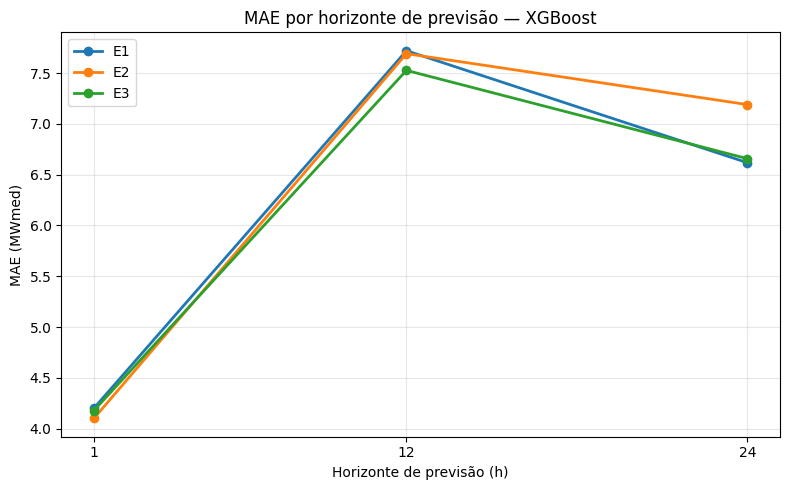

In [49]:
plt.figure(figsize=(8, 5))

for experimento in ['E1', 'E2', 'E3']:

    dados = (
        df_resultados_teste_xgb[
            df_resultados_teste_xgb['experimento'] == experimento
        ]
        .sort_values('horizonte')
    )

    plt.plot(
        dados['horizonte'],
        dados['MAE'],
        marker='o',
        linewidth=2,
        label=experimento
    )

plt.xticks([1, 12, 24])

plt.xlabel('Horizonte de previsão (h)')
plt.ylabel('MAE (MWmed)')
plt.title('MAE por horizonte de previsão — XGBoost')

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

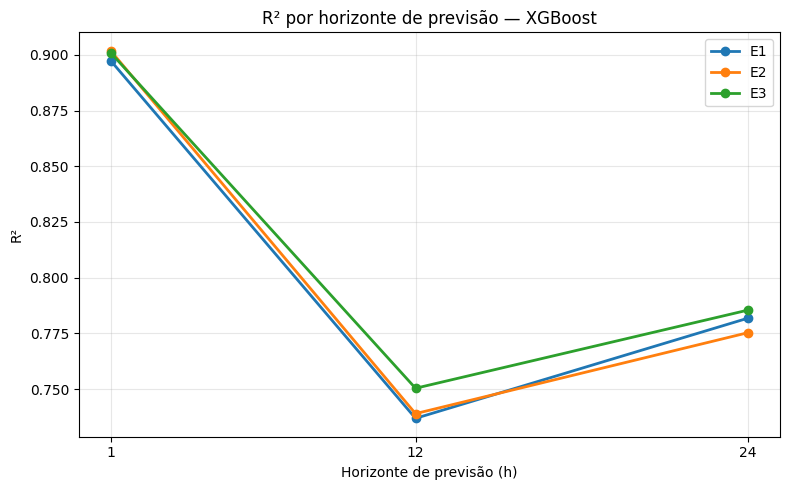

In [50]:
plt.figure(figsize=(8, 5))

for experimento in ['E1', 'E2', 'E3']:

    dados = (
        df_resultados_teste_xgb[
            df_resultados_teste_xgb['experimento'] == experimento
        ]
        .sort_values('horizonte')
    )

    plt.plot(
        dados['horizonte'],
        dados['R2'],
        marker='o',
        linewidth=2,
        label=experimento
    )

plt.xticks([1, 12, 24])

plt.xlabel('Horizonte de previsão (h)')
plt.ylabel('R²')
plt.title('R² por horizonte de previsão — XGBoost')

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()